# Cáncer de origen primario desconocido (CUP) en la red pública chilena
**Egresos hospitalarios GRD 2019–2025 · Análisis exploratorio por preguntas · Análisis de Datos e Inferencia Estadística (UDD)**

Integrantes: Bastián Campos · Maximiliano Mella · Agustín Tapia

**Problema.** En el cáncer de origen primario desconocido (CUP, CIE-10 C80.0) el paciente llega con metástasis, pero no se sabe en qué órgano empezó el tumor. Sin ese dato el tratamiento es empírico y el pronóstico suele ser malo. Este análisis describe cuánto pesa el CUP en los hospitales públicos, quiénes son sus pacientes, cómo los atiende la red y si les va peor que a los pacientes con cáncer metastásico de primario conocido (pulmón, colorrectal, mama, próstata y gástrico). Es la base del *Dashboard CUP Chile*.

**Preguntas que responde** (cada una con su gráfico e interpretación):

| Bloque | Pregunta |
|---|---|
| A. Magnitud | **P1.** ¿Cuántas hospitalizaciones y días-cama genera el CUP y cómo evolucionan? |
| | **P2.** ¿El CUP es el motivo de la hospitalización? |
| B. Paciente | **P3.** ¿Quién es el paciente CUP? |
| | **P4.** ¿A dónde se ha diseminado el cáncer y eso cambia el pronóstico? |
| C. Atención | **P5.** ¿Por dónde llega y quién lo atiende? |
| | **P6.** ¿Cómo sale del hospital y vuelve a hospitalizarse? |
| | **P7.** ¿Cuántos recursos usa? |
| D. Comparación | **P8.** ¿El CUP muere más que los cánceres metastásicos de primario conocido? |
| | **P9.** ¿Se explica porque llega más grave o más viejo? |
| | **P10.** ¿Cambia la conclusión si se suma el C80.9 (CUP potencial)? |
| | **P11.** ¿Cómo se distribuye el CUP en el territorio y hay zonas fuera de lo esperable? |

**Cómo correrlo en VS Code**
1. Elegir el kernel de Python (arriba a la derecha) y usar **Run All**.
2. Requiere `pandas`, `pyarrow`, `matplotlib`, `scipy` y `statsmodels`; `plotly` y `kaleido` son opcionales (gráficos interactivos).
3. Si existe `BD/GRD_grupos_estudio_2019_2025.parquet` tarda alrededor de un minuto. Si no existe, lee los `.txt` de `BD/GRD_C80/` (unos 2 minutos más).

## 0. Configuración

In [1]:
import io
import re
import subprocess
import collections
import datetime as dt
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import FancyBboxPatch, Rectangle
from scipy import stats
from IPython.display import display

try:
    import pyarrow  # noqa: F401  (pandas lo usa para leer y escribir .parquet)
except ImportError:
    raise ImportError('Falta pyarrow para leer la base .parquet: ejecutar  pip install pyarrow  en la terminal y reiniciar el kernel.')

try:
    import plotly.graph_objects as go
    import plotly.io as pio
    pio.renderers.default = 'plotly_mimetype+notebook_connected'
    HAY_PLOTLY = True
except ImportError:
    HAY_PLOTLY = False
    print('Plotly no está instalado: se omiten los gráficos interactivos (pip install plotly kaleido).')

# >>> Carpeta donde está este notebook. Si no corresponde, poner la ruta completa <<<
CARPETA_PROYECTO = Path.cwd()

RUTA_RAR = CARPETA_PROYECTO / 'BD' / 'GRD_C80.rar'                     # comprimido con los .txt (opcional)
RUTA_TXT = CARPETA_PROYECTO / 'BD' / 'GRD_C80'                         # .txt descomprimidos
ANIOS = range(2019, 2026)                                              # años GRD incluidos (2019-2025)
ARCHIVO_GRUPOS = CARPETA_PROYECTO / 'BD' / f'GRD_grupos_estudio_{ANIOS[0]}_{ANIOS[-1]}.parquet'
CARPETA_FIG = CARPETA_PROYECTO / 'figuras'                             # PNG para el informe y la presentación
EDAD_MINIMA = 18                                                       # solo adultos
REHACER_EXTRACCION = False                                       # True = volver a leer los .txt

CARPETA_FIG.mkdir(exist_ok=True)
print('Carpeta del proyecto:      ', CARPETA_PROYECTO, CARPETA_PROYECTO.exists())
print('Carpeta con los .txt:      ', RUTA_TXT.exists())
print('Base .parquet encontrada:  ', ARCHIVO_GRUPOS.exists())
pd.set_option('display.max_columns', 50)
pd.set_option('display.width', 200)

Carpeta del proyecto:       C:\UDD\2026_S2\Analisis Datos\Proyecto True
Carpeta con los .txt:       True
Base .parquet encontrada:   True


## 1. Grupos de estudio

| Grupo | Diagnóstico | Código CIE-10 del tumor primario | Uso |
|---|---|---|---|
| 1 | Cáncer de origen primario desconocido (**CUP**) | C80.0 | análisis principal |
| 2 | Cáncer de pulmón metastásico | C34 | comparación |
| 3 | Cáncer colorrectal metastásico | C18–C20 | comparación |
| 4 | Cáncer de mama metastásico | C50 | comparación |
| 5 | Cáncer de próstata metastásico | C61 | comparación |
| 6 | Cáncer gástrico metastásico | C16 | comparación |
| — | **CUP potencial** (tumor maligno sin especificar) | C80.9 | solo análisis de sensibilidad (P10) |

**Estrategia de identificación** (recomendación de la profesora): el análisis principal usa **solo C80.0**. El C80.9 es otra categoría de la CIE-10 y no se trata como equivalente: se reporta **por separado** como análisis de sensibilidad.

**Reglas** (los códigos se buscan en los 35 diagnósticos de cada egreso):
- *Metastásico* = el egreso tiene además un código de metástasis **C77, C78 o C79**.
- Los grupos 2–6 no pueden tener ningún C80.
- Se excluyen: egresos con más de uno de los 5 primarios, egresos con C80.0 o C80.9 **y** alguno de los 5 primarios (contradictorio) y menores de 18 años.

**Problemas de formato que se corrigen al leer:** cada año tiene distinta codificación (UTF-8, UTF-16, latin-1); 2023 y 2025 traen fechas DD-MM-AAAA; 2024 y 2025 llaman `ID_BENEFICIARIO` al ID del paciente; 2022 tiene 1 fila con 130 campos; el peso GRD usa coma decimal; 2019 y 2025 se llaman `GRD_PUBLICO_AAAA.txt`. **2025 no trae fecha de nacimiento**: solo `TRAMO_EDAD` en tramos de 5 años, así que su edad es el punto medio del tramo (80–84 → 82,5) y el tramo 15–19 se excluye completo. La columna `EDAD_ORIGEN` indica de dónde salió la edad.

In [2]:
ENCODING = {2019: 'utf-8', 2020: 'utf-8', 2021: 'utf-8-sig', 2022: 'utf-16', 2023: 'utf-16',
            2024: 'cp1252', 2025: 'utf-8'}
PRIMARIOS = {'Pulmón': {'C34'}, 'Colorrectal': {'C18', 'C19', 'C20'}, 'Mama': {'C50'},
             'Próstata': {'C61'}, 'Gástrico': {'C16'}}
METASTASIS = {'C77', 'C78', 'C79'}
ORDEN = ['CUP', 'Pulmón', 'Colorrectal', 'Mama', 'Próstata', 'Gástrico']
CUP_POT = 'CUP potencial (C80.9)'
FECHAS = ['FECHA_NACIMIENTO', 'FECHA_INGRESO', 'FECHAALTA', 'FECHAINTERV1', 'FECHAPROCEDIMIENTO1'] + \
         [f'FECHATRASLADO{i}' for i in range(1, 10)]


def fecha_iso(s):
    """Deja todas las fechas en AAAA-MM-DD (2023 y 2025 vienen en DD-MM-AAAA)."""
    s = s.strip()[:10]
    for fmt in ('%Y-%m-%d', '%d-%m-%Y'):
        try:
            return dt.datetime.strptime(s, fmt).date().isoformat()
        except ValueError:
            pass
    return ''


def clasificar(codigos):
    """Devuelve (grupo, motivo_exclusion) para la lista de diagnósticos de un egreso."""
    c3 = {c[:3] for c in codigos}
    primarios = [g for g, cods in PRIMARIOS.items() if c3 & cods]
    if any(c.startswith('C80.0') for c in codigos):
        return (None, 'C80.0 con primario conocido') if primarios else ('CUP', None)
    if any(c.startswith('C80.9') for c in codigos):
        return (None, 'C80.9 con primario conocido') if primarios else (CUP_POT, None)
    if not primarios or 'C80' in c3 or not (c3 & METASTASIS):
        return None, None
    if len(primarios) > 1:
        return None, 'más de un primario'
    return primarios[0], None


def abrir_anio(anio):
    """Abre el GRD del año desde la carpeta (GRD2020.txt o GRD_PUBLICO_2019.txt) o directo desde el .rar."""
    nombres = [f'GRD{anio}.txt', f'GRD_PUBLICO_{anio}.txt']
    for nombre in nombres:
        if (RUTA_TXT / nombre).exists():
            return open(RUTA_TXT / nombre, encoding=ENCODING[anio], errors='replace', newline=''), None
    if not RUTA_RAR.exists():
        raise FileNotFoundError(f'No se encontró {" ni ".join(nombres)} en {RUTA_TXT} ni {RUTA_RAR}. '
                                'Revisa CARPETA_PROYECTO en la celda 0.')
    p = subprocess.Popen(['tar', '-xOf', str(RUTA_RAR), f'GRD_C80/{nombres[0]}'], stdout=subprocess.PIPE)
    return io.TextIOWrapper(p.stdout, encoding=ENCODING[anio], errors='replace', newline=''), p

## 2. Extracción
Se leen los ~6,94 millones de egresos línea por línea y solo se guardan los que pertenecen a algún grupo. El resultado se guarda en `.parquet`, que se lee en segundos.

In [3]:
def edad_desde_tramo(tramo):
    """'[80 - 84 años]' -> (80, 82.5): inicio del tramo y su punto medio. 2025 no trae fecha de nacimiento."""
    numeros = re.findall(r'\d+', tramo)
    if len(numeros) < 2:
        return None, None
    desde, hasta = int(numeros[0]), int(numeros[1])
    return desde, (desde + hasta + 1) / 2


def extraer(anio, excluidos):
    f, proc = abrir_anio(anio)
    header = f.readline().rstrip('\r\n').lstrip('\ufeff').split('|')
    header = ['CIP_ENCRIPTADO' if c == 'ID_BENEFICIARIO' else c for c in header]
    if 'DIAGNOSTICO1' not in header:
        raise ValueError(f'GRD{anio}: no se pudo leer el encabezado. Revisa que el archivo exista y no esté dañado.')
    diag = [header.index(f'DIAGNOSTICO{i}') for i in range(1, 36)]
    fechas = [c for c in FECHAS if c in header]
    filas, total = [], 0
    for line in f:
        v = line.rstrip('\r\n').split('|')
        if len(v) != len(header):            # fila mal formada de 2022
            continue
        total += 1
        codigos = [v[j].strip().upper() for j in diag if v[j].strip()]
        grupo, motivo = clasificar(codigos)
        if motivo:
            excluidos[motivo] += 1
        if not grupo:
            continue
        fila = {k: ('' if x.strip().upper() == 'DESCONOCIDO' else x.strip()) for k, x in zip(header, v)}
        for c in fechas:
            fila[c] = fecha_iso(fila[c])
        edad, origen = None, ''
        if fila.get('FECHA_NACIMIENTO') and fila['FECHA_INGRESO']:
            edad = (dt.date.fromisoformat(fila['FECHA_INGRESO']) - dt.date.fromisoformat(fila['FECHA_NACIMIENTO'])).days / 365.25
            origen = 'fecha de nacimiento'
        elif fila.get('TRAMO_EDAD'):
            desde, edad = edad_desde_tramo(fila['TRAMO_EDAD'])
            origen = 'punto medio del tramo'
            if desde is not None and desde < EDAD_MINIMA:     # el tramo 15-19 se excluye completo
                edad = 0
        if edad is not None and edad < EDAD_MINIMA:
            excluidos[f'menor de {EDAD_MINIMA} años'] += 1
            continue
        peso = fila['IR_29301_PESO'].replace(',', '.')
        fila['IR_29301_PESO'] = '0' + peso if peso.startswith('.') else peso
        fila['ANIO'], fila['GRUPO'] = anio, grupo
        fila['EDAD'], fila['EDAD_ORIGEN'] = (round(edad, 2) if edad is not None else None), origen
        filas.append(fila)
    f.close()
    if proc:
        proc.wait()
    return header, filas, total


if REHACER_EXTRACCION or not ARCHIVO_GRUPOS.exists():
    todas, excluidos, totales, columnas = [], collections.Counter(), {}, ['ANIO', 'GRUPO', 'EDAD', 'EDAD_ORIGEN']
    for anio in ANIOS:
        cols, filas, totales[anio] = extraer(anio, excluidos)
        columnas += [c for c in cols if c not in columnas]     # 2025 trae TRAMO_EDAD y no FECHA_NACIMIENTO ni COMUNA
        todas += filas
        print(f'{anio}: {totales[anio]:,} egresos leídos -> {len(filas):,} en los grupos')
    base = pd.DataFrame(todas, columns=columnas)
    texto = base.columns.difference(['ANIO', 'EDAD'])
    base[texto] = base[texto].replace('', None)               # vacío = dato faltante
    base['ANIO'] = base['ANIO'].astype('int16')
    base['EDAD'] = base['EDAD'].astype(float)
    base.to_parquet(ARCHIVO_GRUPOS, index=False)
    print('\nTotal egresos leídos:', f'{sum(totales.values()):,}')
    print('Excluidos:', dict(excluidos))
    print(base['GRUPO'].value_counts().to_string())
    print('Guardado en', ARCHIVO_GRUPOS)
    del todas, base
else:
    print(f'Usando la base ya generada: {ARCHIVO_GRUPOS} (para rehacerla, poner REHACER_EXTRACCION = True)')

Usando la base ya generada: C:\UDD\2026_S2\Analisis Datos\Proyecto\BD\GRD_grupos_estudio_2019_2025.parquet (para rehacerla, poner REHACER_EXTRACCION = True)


## 3. Datos: preparación, descripción y calidad
### 3.1 Variables derivadas
Además de las variables del GRD se construyen: edad, días de estancia, fallecimiento, gravedad máxima (severidad GRD 3), paso por UCI y por pabellón, sitios de metástasis, especialidad y procedencia agrupadas, condición al alta, reingreso a 30 días y si al paciente CUP se le encontró después el primario.

In [4]:
todos = pd.read_parquet(ARCHIVO_GRUPOS)
for c in ['FECHA_INGRESO', 'FECHAALTA']:
    todos[c] = pd.to_datetime(todos[c], errors='coerce')
DIAG = [f'DIAGNOSTICO{i}' for i in range(1, 36)]
SERVICIOS = ['SERVICIOINGRESO'] + [f'SERVICIOTRASLADO{i}' for i in range(1, 10)] + ['SERVICIOALTA']

todos['EDAD'] = todos['EDAD'].astype(float)                 # exacta 2019-2024; punto medio del tramo en 2025
todos['DIAS_ESTADA'] = (todos['FECHAALTA'] - todos['FECHA_INGRESO']).dt.days
todos['PESO_GRD'] = pd.to_numeric(todos['IR_29301_PESO'], errors='coerce')
todos['SEVERIDAD'] = pd.to_numeric(todos['IR_29301_SEVERIDAD'], errors='coerce')
todos['FALLECIDO'] = (todos['TIPOALTA'] == 'FALLECIDO').astype(int)
todos['SEV3'] = (todos['SEVERIDAD'] == 3).astype(int)
todos['URGENCIA'] = (todos['TIPO_INGRESO'] == 'URGENCIA').astype(int)
todos['MUJER'] = (todos['SEXO'] == 'MUJER').astype(int)
todos['USO_PABELLON'] = (pd.to_numeric(todos['USOSPABELLON'], errors='coerce').fillna(0) > 0).astype(int)
todos['UCI'] = todos[SERVICIOS].apply(lambda s: s.fillna('').str.contains('INTENSIV')).any(axis=1).astype(int)
todos['HOSP_DOM'] = (todos['TIPOALTA'] == 'HOSPITALIZACIÓN DOMICILIARIA').astype(int)

# Sitios de metástasis (en cualquiera de los 35 diagnósticos)
SITIOS = {'Hígado': ('C78.7',), 'Peritoneo': ('C78.6',), 'Pulmón': ('C78.0',), 'Hueso': ('C79.5',),
          'Cerebro': ('C79.3',), 'Ganglios linfáticos': ('C77',), 'Pleura': ('C78.2',), 'Suprarrenal': ('C79.7',)}
diag_txt = todos[DIAG].fillna('')
for sitio, prefijos in SITIOS.items():
    todos[f'MET_{sitio}'] = diag_txt.apply(lambda s: s.str.startswith(prefijos)).any(axis=1).astype(int)

# Diagnóstico principal: ¿es el propio cáncer del grupo, una metástasis u otra causa?
CODIGO_GRUPO = {'CUP': ('C80.0',), CUP_POT: ('C80.9',), 'Pulmón': ('C34',), 'Colorrectal': ('C18', 'C19', 'C20'),
                'Mama': ('C50',), 'Próstata': ('C61',), 'Gástrico': ('C16',)}
dx1 = todos['DIAGNOSTICO1'].fillna('')
propio = pd.Series([d.startswith(CODIGO_GRUPO[g]) for d, g in zip(dx1, todos['GRUPO'])], index=todos.index)
todos['TIPO_DX1'] = np.select([propio, dx1.str[:3].isin(METASTASIS)],
                              ['El propio cáncer del grupo', 'Una metástasis (C77–C79)'], 'Otra causa')

# Agrupaciones para la trayectoria del paciente
proc = todos['TIPO_PROCEDENCIA'].fillna('')
todos['LLEGADA'] = np.select(
    [proc.str.contains('EMERGENCIA|APS URGENCIA'), proc.str.startswith('CENTRO ESPECIALIDADES'),
     proc.str.contains('HOSPITALES')],
    ['Urgencia', 'Consulta de especialidad', 'Otro hospital'], 'Otra procedencia')
esp = todos['ESPECIALIDAD_MEDICA'].fillna('')
todos['ESPECIALIDAD'] = np.select(
    [esp.str.contains('NEURO'), esp == 'MEDICINA INTERNA', esp.str.contains('ONCOLOG'), esp.str.contains('CIRUG')],
    ['Neurología / neurocirugía', 'Medicina interna', 'Oncología', 'Cirugía'], 'Otra especialidad')
alta = todos['TIPOALTA'].fillna('')
todos['SALIDA'] = np.select(
    [alta == 'FALLECIDO', alta == 'DOMICILIO', alta == 'HOSPITALIZACIÓN DOMICILIARIA', alta.str.startswith('DERIVACI')],
    ['Fallece', 'Alta a domicilio', 'Hospitalización domiciliaria', 'Derivado a otro centro'], 'Otra salida')
todos['PREVISION_G'] = todos['PREVISION'].fillna('').str.extract(r'FONASA INSTITUCIONAL - \(MAI\) ([A-D])')[0] \
    .map(lambda x: f'FONASA {x}' if isinstance(x, str) else 'Otra')

# Reingreso a 30 días: otra hospitalización por cualquiera de estos cánceres dentro de 30 días del alta.
# El ID cifrado cambia entre 2020 y 2021 y 2025 no tiene seguimiento posterior: esos altas quedan sin dato.
todos = todos.sort_values(['CIP_ENCRIPTADO', 'FECHA_INGRESO']).reset_index(drop=True)
siguiente = todos.groupby('CIP_ENCRIPTADO')['FECHA_INGRESO'].shift(-1)
dias_hasta = (siguiente - todos['FECHAALTA']).dt.days
observable = (todos['FALLECIDO'] == 0) & ~todos['FECHAALTA'].between('2020-12-02', '2020-12-31') & \
             (todos['FECHAALTA'] <= '2025-12-01')
todos['REINGRESO30'] = np.where(observable, dias_hasta.between(0, 30).astype(float), np.nan)

df = todos[todos['GRUPO'].isin(ORDEN)].copy()
df['GRUPO'] = pd.Categorical(df['GRUPO'], ORDEN)
pot = todos[todos['GRUPO'] == CUP_POT].copy()
print(f'Análisis principal: {len(df):,} egresos de {df.CIP_ENCRIPTADO.nunique():,} pacientes'.replace(',', '.'))
print(f'CUP potencial (C80.9), solo para sensibilidad: {len(pot)} egresos')

Análisis principal: 60.816 egresos de 41.305 pacientes
CUP potencial (C80.9), solo para sensibilidad: 1042 egresos


### 3.2 Estilo de los gráficos
Paleta por significado, igual en todo el documento y en el dashboard: **violeta** = CUP, **naranjo** = el paciente muere (lo desfavorable), **azul** = lo favorable, **gris** = contexto (los otros cinco cánceres). Los resultados se expresan como frecuencias ("22 de cada 100 hospitalizaciones") y el título de cada gráfico dice la conclusión.

In [5]:
plt.rcParams.update({
    'figure.facecolor': '#fcfcfb', 'axes.facecolor': '#fcfcfb', 'savefig.facecolor': '#fcfcfb',
    'axes.edgecolor': '#c3c2b7', 'axes.labelcolor': '#52514e', 'xtick.color': '#52514e', 'ytick.color': '#52514e',
    'axes.grid': True, 'grid.color': '#e1e0d9', 'grid.linewidth': 0.7,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.titlesize': 11.5, 'axes.titleweight': 'semibold', 'axes.titlelocation': 'left', 'axes.titlecolor': '#0b0b0b',
    'font.size': 10.5, 'figure.dpi': 110, 'font.family': 'sans-serif',
    'font.sans-serif': ['Segoe UI', 'DejaVu Sans'],        # solo pesos "semibold" y "normal"
    'text.parse_math': False,
})

naranjo = '#eb6834'        # lo desfavorable: el paciente muere
azul = '#2a78d6'           # lo favorable
amarillo = '#eda100'       # referencia externa (franja de la pandemia)
violeta = '#4a3aa7'        # el grupo en estudio: CUP
gris_marca = '#b5b3ab'     # contexto: los otros cinco cánceres
tinta, gris_texto, gris_suave = '#0b0b0b', '#52514e', '#898781'
fondo_icono = '#e8e7e1'
COLOR_CUP = violeta
FUENTE = (f'Fuente: egresos GRD FONASA {ANIOS[0]}–{ANIOS[-1]}, hospitales públicos, pacientes de {EDAD_MINIMA} años o más '
          f'(n = {len(df):,} hospitalizaciones).'.replace(f'{len(df):,}', f'{len(df):,}'.replace(',', '.')))


def color_grupo(g):
    return COLOR_CUP if g == 'CUP' else gris_marca


def poner_titulo(figura, titulo, subtitulo, ajustar=True):
    """Título (la conclusión) y subtítulo (cómo leer el gráfico) arriba a la izquierda; fuente al pie."""
    alto = figura.get_size_inches()[1]
    espacio = (0.62 + 0.2 * (subtitulo.count('\n') + 1)) / alto
    pie = 0.32 / alto
    figura.text(0.01, 1 - 0.1 / alto, titulo, fontsize=15, fontweight='semibold', color=tinta, ha='left', va='top')
    figura.text(0.01, 1 - 0.46 / alto, subtitulo, fontsize=10.5, color=gris_texto, ha='left', va='top', linespacing=1.4)
    figura.text(0.01, 0.08 / alto, FUENTE, fontsize=8.5, color=gris_suave, ha='left', va='bottom')
    if ajustar:
        figura.tight_layout(rect=(0, pie, 1, 1 - espacio))
    else:
        figura.subplots_adjust(top=1 - espacio - 0.055)


def coma(x, decimales=1):
    return f'{x:.{decimales}f}'.replace('.', ',')


def de100(pct):
    """41.6 -> '42' (se lee 'de cada 100')."""
    return f'{pct:.0f}'


def miles(n):
    return f'{n:,.0f}'.replace(',', '.')


def ic_prop(x, n, z=1.96):
    """IC 95 % de Wilson para una proporción, en %."""
    x, n = np.asarray(x, float), np.asarray(n, float)
    p = x / n
    centro = (p + z**2 / (2 * n)) / (1 + z**2 / n)
    margen = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / (1 + z**2 / n)
    return (centro - margen) * 100, (centro + margen) * 100


def matriz_iconos(eje, cantidades, colores, columnas=10):
    """Matriz de 10 x 10: cantidades=[22, 78] con colores=[naranjo, fondo] dibuja '22 de cada 100'."""
    k = 0
    for cantidad, color in zip(cantidades, colores):
        for _ in range(cantidad):
            fila, columna = divmod(k, columnas)
            eje.add_patch(FancyBboxPatch((columna + 0.09, -fila + 0.09), 0.82, 0.82,
                                         boxstyle='round,pad=0,rounding_size=0.14', facecolor=color, edgecolor='none'))
            k += 1
    filas = int(np.ceil(k / columnas))
    eje.set_xlim(0, columnas)
    eje.set_ylim(-filas + 1, 1)
    eje.set_aspect('equal')
    eje.axis('off')


def recuadro(eje, etiqueta, valor, detalle, color_marca=None):
    """Recuadro con un número grande, como en un tablero de control."""
    eje.set_axis_off()
    eje.add_patch(FancyBboxPatch((0.015, 0.04), 0.97, 0.92, boxstyle='round,pad=0,rounding_size=0.04',
                                 transform=eje.transAxes, facecolor='white', edgecolor='#e1e0d9', linewidth=1))
    if color_marca:
        eje.add_patch(FancyBboxPatch((0.015, 0.04), 0.025, 0.92, boxstyle='square,pad=0', transform=eje.transAxes,
                                     facecolor=color_marca, edgecolor='none'))
    eje.text(0.08, 0.80, etiqueta, transform=eje.transAxes, fontsize=10, color=gris_texto, va='top')
    eje.text(0.08, 0.47, valor, transform=eje.transAxes, fontsize=21, fontweight='semibold', color=tinta, va='center')
    eje.text(0.08, 0.17, detalle, transform=eje.transAxes, fontsize=9, color=gris_suave, va='center')


def rotular_finales(eje, x, finales, separacion, texto):
    """Escribe el nombre y valor al final de cada línea, separando los textos que chocarían."""
    ultimo = None
    for g, v in sorted(finales.items(), key=lambda kv: kv[1]):
        y_txt = v if ultimo is None else max(v, ultimo + separacion)
        eje.annotate(texto(g, v), xy=(x, v), xytext=(x + 0.08, y_txt), va='center', fontsize=10,
                     color=tinta, fontweight='semibold' if g == 'CUP' else 'normal')
        ultimo = y_txt


def lineas_por_grupo(eje, xs, tabla, banda=None):
    """Una línea por grupo: CUP en violeta y gruesa, los demás en gris. banda = (lo, hi) del CUP."""
    if banda is not None:
        eje.fill_between(xs, banda[0], banda[1], color=COLOR_CUP, alpha=0.14, linewidth=0)
    for g in ORDEN:
        if g not in tabla.columns:
            continue
        cup = g == 'CUP'
        eje.plot(xs, tabla[g], color=color_grupo(g), linewidth=3 if cup else 1.8, marker='o',
                 markersize=6 if cup else 4.5, zorder=3 if cup else 2)


def puntos_por_grupo(eje, valores, filas, texto=None, xmax=100, sep=None):
    """Lollipop horizontal: una fila por grupo, CUP en violeta. Escribe el valor a la derecha del punto."""
    y = np.arange(len(filas))[::-1]
    colores = [color_grupo(g) for g in filas]
    v = valores.loc[filas]
    eje.hlines(y, 0, v, color=colores, linewidth=2.5)
    eje.scatter(v, y, s=[110 if g == 'CUP' else 70 for g in filas], color=colores, zorder=3)
    for yi, g, val in zip(y, filas, v):
        eje.text(val + (sep or xmax * 0.03), yi, texto(val) if texto else de100(val), va='center', fontsize=10.5,
                 color=tinta, fontweight='semibold' if g == 'CUP' else 'normal')
    eje.set_xlim(0, xmax)
    eje.grid(axis='y', visible=False)
    return y


def guardar(figura, nombre):
    figura.savefig(CARPETA_FIG / f'{nombre}.png', dpi=200)
    plt.show()


def plotly_base(fig, titulo, subtitulo, alto=620):
    """Mismo estilo que matplotlib: título con la conclusión, subtítulo y fuente al pie."""
    fig.update_layout(
        title=dict(text=f'<b>{titulo}</b><br><span style="font-size:13px;color:{gris_texto}">{subtitulo}</span>',
                   x=0.01, xanchor='left', y=0.97, font=dict(size=19, color=tinta)),
        font=dict(family='Segoe UI, Arial', size=13, color=tinta), paper_bgcolor='#fcfcfb', plot_bgcolor='#fcfcfb',
        width=1300, height=alto, margin=dict(l=30, r=30, t=110, b=50))
    fig.add_annotation(text=FUENTE, x=0, y=-0.08, xref='paper', yref='paper', showarrow=False, xanchor='left',
                       font=dict(size=11, color=gris_suave))
    return fig


def guardar_plotly(fig, nombre):
    """HTML interactivo + PNG estático (el PNG requiere kaleido)."""
    fig.write_html(CARPETA_FIG / f'{nombre}.html', include_plotlyjs='cdn')
    try:
        fig.write_image(CARPETA_FIG / f'{nombre}.png', scale=2)
    except Exception as error:  # kaleido no instalado o sin navegador
        print('No se pudo exportar el PNG de Plotly:', error)
    fig.show()

### 3.3 Fuente y estructura de los datos
- **Fuente:** bases públicas de egresos hospitalarios agrupados por **GRD** (Grupos Relacionados por el Diagnóstico) que publica FONASA para los hospitales públicos, años 2019–2025. Se descargan como archivos de texto separados por `|`.
- **Unidad de análisis:** el **egreso** (una hospitalización). Un mismo paciente puede tener varios.
- **Estructura:** unas 128 columnas por egreso: datos del paciente, del hospital, 35 diagnósticos CIE-10, 30 procedimientos, fechas, traslados y la clasificación GRD (código, severidad, riesgo de muerte y peso).
- **Pertinencia:** el GRD es la única base nacional con todos los diagnósticos codificados de cada hospitalización pública, lo que permite identificar el CUP (C80.0) y saber si hay metástasis.

In [6]:
VARIABLES = [
    ('ANIO', 'Año del egreso', 'numérica (entera)'),
    ('GRUPO', 'Grupo de estudio (derivada de los 35 diagnósticos)', 'categórica'),
    ('SEXO', 'Sexo del paciente', 'categórica'),
    ('EDAD', 'Edad al ingreso (2025: punto medio del tramo)', 'numérica'),
    ('PREVISION', 'Previsión de salud (FONASA A–D, ISAPRE, otras)', 'categórica'),
    ('SERVICIO_SALUD', 'Servicio de Salud del hospital', 'categórica'),
    ('TIPO_PROCEDENCIA', 'Desde dónde llega el paciente', 'categórica'),
    ('TIPO_INGRESO', 'Urgencia o programada', 'categórica'),
    ('ESPECIALIDAD_MEDICA', 'Especialidad que da el alta', 'categórica'),
    ('FECHA_INGRESO', 'Fecha de ingreso', 'fecha'),
    ('FECHAALTA', 'Fecha de alta', 'fecha'),
    ('DIAS_ESTADA', 'Días de estancia (alta − ingreso)', 'numérica (derivada)'),
    ('TIPOALTA', 'Condición al alta (domicilio, fallecido, derivación…)', 'categórica'),
    ('DIAGNOSTICO1', 'Diagnóstico principal CIE-10 (hay 35)', 'categórica (código)'),
    ('USOSPABELLON', 'Veces que usó pabellón', 'numérica'),
    ('IR_29301_SEVERIDAD', 'Severidad GRD (0 a 3)', 'ordinal'),
    ('IR_29301_MORTALIDAD', 'Riesgo de muerte GRD (0 a 3)', 'ordinal'),
    ('IR_29301_PESO', 'Peso GRD: consumo relativo de recursos', 'numérica'),
]
dicc = pd.DataFrame(VARIABLES, columns=['Variable', 'Descripción', 'Tipo']).set_index('Variable')
dicc['Valores distintos'] = [df[v].nunique() for v in dicc.index]
dicc['% faltante'] = [round(df[v].isna().mean() * 100, 2) for v in dicc.index]
dicc

,Descripción,Tipo,Valores distintos,% faltante
Variable,,,,
ANIO,Año del egreso,numérica (entera),7,0.00
GRUPO,Grupo de estudio (derivada de los 35 diagnósti...,categórica,6,0.00
SEXO,Sexo del paciente,categórica,2,0.01
EDAD,Edad al ingreso (2025: punto medio del tramo),numérica,6473,0.00
PREVISION,"Previsión de salud (FONASA A–D, ISAPRE, otras)",categórica,14,0.00
SERVICIO_SALUD,Servicio de Salud del hospital,categórica,31,0.00
TIPO_PROCEDENCIA,Desde dónde llega el paciente,categórica,17,0.00
TIPO_INGRESO,Urgencia o programada,categórica,4,0.00
ESPECIALIDAD_MEDICA,Especialidad que da el alta,categórica,58,0.01


### 3.4 Egresos por grupo y año

In [7]:
tabla_n = pd.crosstab(todos['GRUPO'], todos['ANIO'], margins=True, margins_name='Total').reindex(ORDEN + [CUP_POT, 'Total'])
tabla_n['Pacientes'] = todos.groupby('GRUPO')['CIP_ENCRIPTADO'].nunique().reindex(tabla_n.index)
tabla_n.loc['Total', 'Pacientes'] = df['CIP_ENCRIPTADO'].nunique()
tabla_n.loc['Total'] = tabla_n.loc[ORDEN].sum()          # el total es solo de los 6 grupos del análisis principal
tabla_n.loc['Total', 'Pacientes'] = df['CIP_ENCRIPTADO'].nunique()
tabla_n

ANIO,2019,2020,2021,2022,2023,2024,2025,Total,Pacientes
GRUPO,,,,,,,,,
CUP,622,473,479,508,559,597,651,3889,3520.0
Pulmón,1378,968,868,1030,1376,1407,1679,8706,6768.0
Colorrectal,3235,2259,2329,2517,2973,3436,3832,20581,11968.0
Mama,2511,1219,1202,1478,1899,1996,2215,12520,8285.0
Próstata,954,647,708,767,1017,1210,1381,6684,4995.0
Gástrico,1201,1062,1092,1127,1218,1274,1462,8436,6124.0
CUP potencial (C80.9),98,130,138,171,159,176,170,1042,1006.0
Total,9901,6628,6678,7427,9042,9920,11220,60816,41305.0


**Lectura.** Los seis grupos suman **60.816 hospitalizaciones de 41.305 pacientes**; el CUP aporta 3.889 (6,4 de cada 100). 2020 y 2021 tienen menos egresos que 2019 en todos los grupos: la pandemia de COVID-19 postergó hospitalizaciones, sobre todo las programadas (mama cae de 2.511 a 1.219). Desde 2022 se recuperan y en 2025 superan a 2019 en todos los grupos salvo mama. El C80.9 (1.042 egresos) se muestra aparte y no entra al total.

La columna *Pacientes* es aproximada: el ID cifrado cambia entre 2020 y 2021 (ningún paciente coincide entre esos dos años, mientras que entre otros años consecutivos coinciden entre 484 y 932), así que quien se hospitalizó a ambos lados de ese corte se cuenta dos veces.

### 3.5 Datos faltantes

In [8]:
clave = ['SEXO', 'EDAD', 'PREVISION', 'SERVICIO_SALUD', 'TIPO_INGRESO', 'FECHA_INGRESO', 'FECHAALTA', 'TIPOALTA',
         'IR_29301_COD_GRD', 'IR_29301_PESO', 'IR_29301_SEVERIDAD', 'HOSPPROCEDENCIA']
faltantes = pd.DataFrame({'n faltantes': df[clave].isna().sum(), '% faltante': (df[clave].isna().mean() * 100).round(2)})
display(faltantes)
print('Origen de la edad:', df['EDAD_ORIGEN'].value_counts().to_dict())

,n faltantes,% faltante
SEXO,5,0.01
EDAD,0,0.00
PREVISION,0,0.00
SERVICIO_SALUD,1,0.00
TIPO_INGRESO,1,0.00
FECHA_INGRESO,0,0.00
FECHAALTA,0,0.00
TIPOALTA,0,0.00
IR_29301_COD_GRD,1,0.00
IR_29301_PESO,1,0.00


Origen de la edad: {'fecha de nacimiento': 49596, 'punto medio del tramo': 11220}


**Lectura.** Las variables clave están prácticamente completas (menos de 0,02 % de faltantes). `HOSPPROCEDENCIA` está vacía en 89 de cada 100 egresos porque solo se llena cuando el paciente viene derivado de otro hospital; no es un error. `USOSPABELLON` vacío (61 %) significa que no usó pabellón y se cuenta como 0. La edad de los 11.220 egresos de 2025 es aproximada (punto medio del tramo de 5 años, error máximo de ±2,5 años); la de los otros 49.596 se calcula con la fecha de nacimiento.

### 3.6 Estadística descriptiva y valores atípicos

In [9]:
def resumen_num(s):
    q1, med, q3 = s.quantile([.25, .5, .75])
    return pd.Series({'media': s.mean(), 'DE': s.std(), 'mínimo': s.min(), 'p25': q1, 'mediana': med, 'p75': q3,
                      'máximo': s.max()}).round(1)


descriptiva = pd.concat({v: df.groupby('GRUPO', observed=True)[v].apply(resumen_num).unstack()
                         for v in ['EDAD', 'DIAS_ESTADA', 'PESO_GRD']})
display(descriptiva)


def atipicos(s):
    q1, q3 = s.quantile([.25, .75])
    lim = q3 + 1.5 * (q3 - q1)
    return pd.Series({'límite superior (días)': lim, 'n atípicos': (s > lim).sum(),
                      '% atípicos': round((s > lim).mean() * 100, 1), 'máximo': s.max()})


df.groupby('GRUPO', observed=True)['DIAS_ESTADA'].apply(atipicos).unstack()

media    DE  mínimo   p25  mediana   p75  máximo
            GRUPO                                                        
EDAD        CUP           67.8  13.5    18.3  60.0     68.8  77.5   104.1
            Pulmón        67.5  11.2    21.0  61.5     68.0  75.0    98.9
            Colorrectal   63.7  12.9    18.2  56.0     64.8  72.5   110.3
            Mama          58.7  13.9    19.4  47.9     58.7  68.5   104.6
            Próstata      73.5   9.3    20.6  67.5     73.4  80.2   102.5
            Gástrico      65.0  12.5    18.0  57.5     66.4  74.0   101.4
DIAS_ESTADA CUP           12.6  15.4     0.0   3.0      9.0  17.0   371.0
            Pulmón        10.7  11.5     0.0   3.0      7.0  14.0   118.0
            Colorrectal    8.0  11.8     0.0   2.0      4.0   9.0   369.0
            Mama           6.1  11.0     0.0   1.0      3.0   7.0   422.0
            Próstata      10.3  15.6     0.0   2.0      6.0  13.0   447.0
            Gástrico       9.3  12.5     0.0   2.0      5.0  12.0   248.0
PESO_GRD    CUP            1.4   1.0     0.1   0.9      1.2   1.4    11.7
            Pulmón         1.3   0.9     0.0   0.9      1.2   1.3    11.7
            Colorrectal    1.5   1.1     0.0   0.9      1.3   1.6    13.5
            Mama           1.1   0.8     0.0   0.8      1.0   1.2    11.7
            Próstata       1.2   0.9     0.0   0.8      1.0   1.3    11.7
            Gástrico       1.4   1.0     0.0   0.9      1.1   1.4    11.7

,límite superior (días),n atípicos,% atípicos,máximo
GRUPO,,,,
CUP,38.0,186.0,4.8,371.0
Pulmón,30.5,525.0,6.0,118.0
Colorrectal,19.5,1970.0,9.6,369.0
Mama,16.0,1146.0,9.2,422.0
Próstata,29.5,410.0,6.1,447.0
Gástrico,27.0,580.0,6.9,248.0


**Lectura.** La estancia es muy asimétrica: en el CUP la media (12,6 días) supera bastante a la mediana (9), hay 186 egresos atípicos (más de 38 días según la regla 1,5 × RIC) y el máximo es de 371 días. Las estancias largas son clínicamente posibles (complicaciones, cuidados paliativos, espera de cupo), así que **se mantienen**; por eso se reportan medianas y rangos intercuartílicos en vez de promedios. La edad va de 18 a 110 años (110 es inusual pero posible y son casos aislados) y el peso GRD va de 0 a 13,5, dentro del rango de la norma GRD.

## 4. Bloque A — ¿Cuánto pesa el CUP?
### P1. ¿Cuántas hospitalizaciones y días-cama genera el CUP y cómo evolucionan?
Es la primera fila del dashboard: el volumen y la mortalidad de cada año, con su variación.

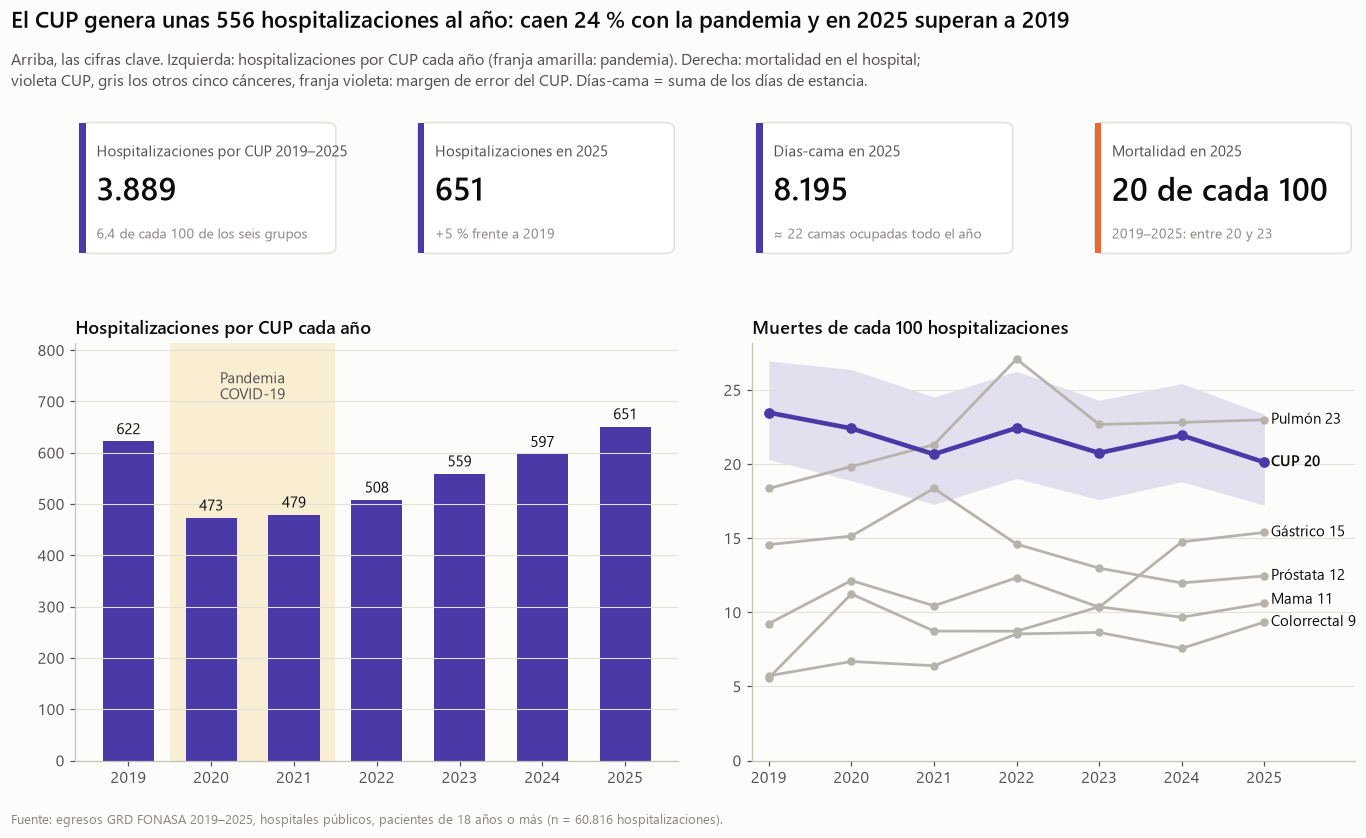

,egresos,dias_cama,mortalidad
ANIO,,,
2019,622,7789,23.5
2020,473,5687,22.4
2021,479,5666,20.7
2022,508,6630,22.4
2023,559,7669,20.8
2024,597,7553,21.9
2025,651,8195,20.1


In [10]:
anual = df.groupby(['ANIO', 'GRUPO'], observed=True).agg(
    egresos=('FALLECIDO', 'size'), muertes=('FALLECIDO', 'sum'), dias_cama=('DIAS_ESTADA', 'sum')).reset_index()
anual['mortalidad'] = anual.muertes / anual.egresos * 100
cup_a = anual[anual.GRUPO == 'CUP'].set_index('ANIO')
ini, fin = ANIOS[0], ANIOS[-1]
total_cup = int(cup_a.egresos.sum())
pct_cup = total_cup / len(df) * 100
cambio = (cup_a.egresos[fin] / cup_a.egresos[ini] - 1) * 100
caida = (cup_a.egresos[2020] / cup_a.egresos[2019] - 1) * 100
lo_a, hi_a = ic_prop(cup_a.muertes, cup_a.egresos)
mort_anual = anual.pivot(index='ANIO', columns='GRUPO', values='mortalidad')

figura = plt.figure(figsize=(13, 7.6))
rejilla = figura.add_gridspec(2, 4, height_ratios=[0.75, 2.2], hspace=0.3, wspace=0.28, left=0.055, right=0.95, bottom=0.09, top=0.86)
recuadro(figura.add_subplot(rejilla[0, 0]), f'Hospitalizaciones por CUP {ini}–{fin}', miles(total_cup),
         f'{coma(pct_cup)} de cada 100 de los seis grupos', COLOR_CUP)
recuadro(figura.add_subplot(rejilla[0, 1]), f'Hospitalizaciones en {fin}', miles(cup_a.egresos[fin]),
         f'{cambio:+.0f} % frente a {ini}'.replace('.', ','), COLOR_CUP)
recuadro(figura.add_subplot(rejilla[0, 2]), f'Días-cama en {fin}', miles(cup_a.dias_cama[fin]),
         f'≈ {cup_a.dias_cama[fin] / 365:.0f} camas ocupadas todo el año', COLOR_CUP)
recuadro(figura.add_subplot(rejilla[0, 3]), f'Mortalidad en {fin}', f'{de100(cup_a.mortalidad[fin])} de cada 100',
         f'{ini}–{fin}: entre {de100(cup_a.mortalidad.min())} y {de100(cup_a.mortalidad.max())}', naranjo)

eje = figura.add_subplot(rejilla[1, :2])
eje.axvspan(2019.5, 2021.5, color=amarillo, alpha=0.16, linewidth=0)
eje.text(2020.5, cup_a.egresos.max() * 1.07, 'Pandemia\nCOVID-19', ha='center', va='bottom', fontsize=9.5, color=gris_texto)
eje.bar(cup_a.index, cup_a.egresos, color=COLOR_CUP, width=0.62)
for x, v in cup_a.egresos.items():
    eje.text(x, v + 8, miles(v), ha='center', va='bottom', fontsize=10, color=tinta)
eje.set_ylim(0, cup_a.egresos.max() * 1.25)
eje.set_xticks(list(ANIOS))
eje.grid(axis='x', visible=False)
eje.set_title('Hospitalizaciones por CUP cada año')

eje = figura.add_subplot(rejilla[1, 2:])
lineas_por_grupo(eje, mort_anual.index, mort_anual, banda=(lo_a, hi_a))
rotular_finales(eje, fin, mort_anual.loc[fin].to_dict(), 1.5, lambda g, v: f'{g} {de100(v)}')
eje.set_xticks(list(ANIOS))
eje.set_xlim(ini - 0.2, fin + 1.1)
eje.set_ylim(0, None)
eje.grid(axis='x', visible=False)
eje.set_title('Muertes de cada 100 hospitalizaciones')
poner_titulo(figura,
             f'El CUP genera unas {cup_a.egresos.mean():.0f} hospitalizaciones al año: caen {abs(caida):.0f} % con la pandemia '
             f'y en {fin} {"superan" if cambio > 0 else "aún no alcanzan"} a {ini}',
             'Arriba, las cifras clave. Izquierda: hospitalizaciones por CUP cada año (franja amarilla: pandemia). '
             'Derecha: mortalidad en el hospital;\nvioleta CUP, gris los otros cinco cánceres, franja violeta: margen de error '
             'del CUP. Días-cama = suma de los días de estancia.', ajustar=False)
guardar(figura, 'P01_magnitud_y_tendencia')
cup_a[['egresos', 'dias_cama', 'mortalidad']].round(1)

**Respuesta.** Entre 2019 y 2025 hubo **3.889 hospitalizaciones por CUP**, unas 556 al año: 6 de cada 100 hospitalizaciones de los seis grupos. Con la pandemia cayeron 24 % (de 622 a 473) y desde 2022 se recuperan: en 2025 llegaron a 651, un 5 % más que en 2019. En 2025 ocuparon **8.195 días-cama**, el equivalente a 22 camas ocupadas todo el año. La mortalidad del CUP se mantiene **entre 20 y 23 de cada 100** cada año; las subidas y bajadas son menores que su margen de error (franja violeta), así que no hay tendencia. Desde 2023 pulmón queda levemente por encima.

### P2. ¿El CUP es el motivo de la hospitalización?
El GRD trae hasta 35 diagnósticos por egreso; el primero es el **diagnóstico principal** (el motivo de la hospitalización). Esta pregunta revisa la calidad de la definición: ¿el C80.0 aparece como motivo o como diagnóstico secundario?

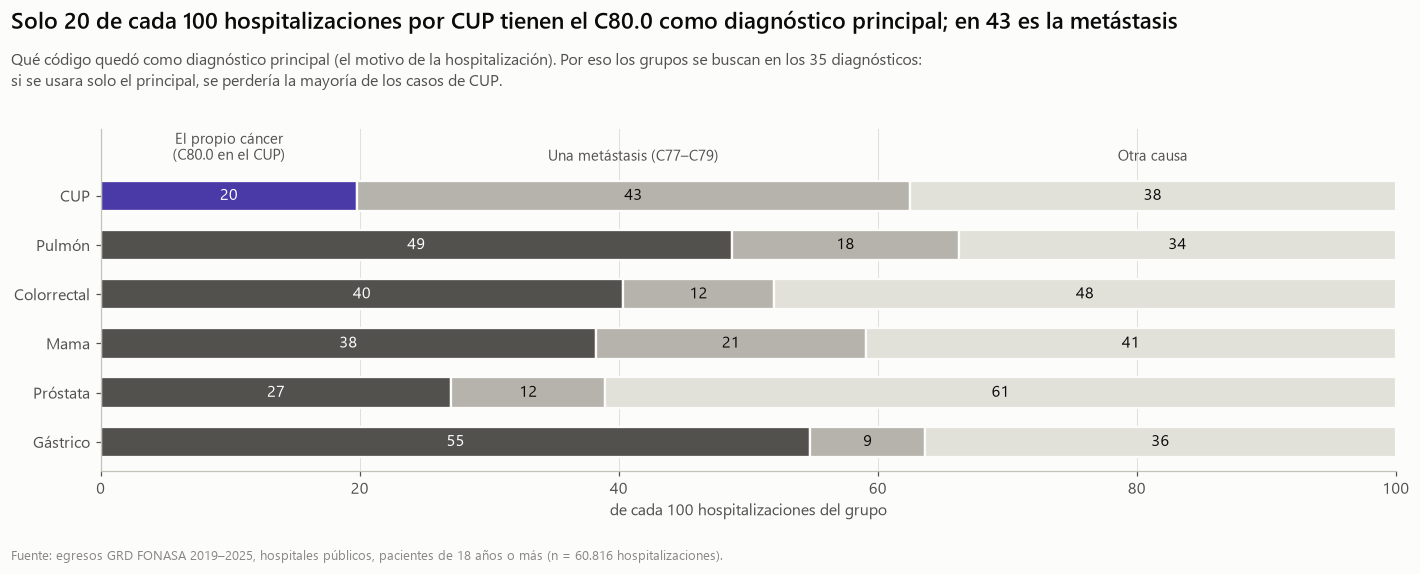

,egresos,de cada 100,Descripción
DIAGNOSTICO1,,,
C80.0,770,19.8,CUP (el propio diagnóstico)
C78.6,356,9.2,Metástasis en peritoneo
C78.7,277,7.1,Metástasis en hígado
C79.5,251,6.5,Metástasis en hueso
C79.3,227,5.8,Metástasis en cerebro
C78.0,183,4.7,Metástasis en pulmón
C78.2,153,3.9,Metástasis en pleura
I26.9,90,2.3,Tromboembolismo pulmonar
Z51.1,79,2.0,Sesión de quimioterapia


In [11]:
CATS_DX = ['El propio cáncer del grupo', 'Una metástasis (C77–C79)', 'Otra causa']
dx = (pd.crosstab(df['GRUPO'], df['TIPO_DX1'], normalize='index') * 100).reindex(columns=CATS_DX).loc[ORDEN]
p_propio, p_met = dx.loc['CUP', CATS_DX[0]], dx.loc['CUP', CATS_DX[1]]

figura, eje = plt.subplots(figsize=(13, 5.2))
y = np.arange(len(ORDEN))[::-1]
izquierda = np.zeros(len(ORDEN))
tonos = {CATS_DX[0]: '#52514e', CATS_DX[1]: gris_marca, CATS_DX[2]: '#e1e0d9'}
for cat in CATS_DX:
    colores = [COLOR_CUP if (g == 'CUP' and cat == CATS_DX[0]) else tonos[cat] for g in ORDEN]
    eje.barh(y, dx[cat], left=izquierda, color=colores, height=0.62, edgecolor='#fcfcfb', linewidth=1.5)
    for yi, l, v, c in zip(y, izquierda, dx[cat], colores):
        if v >= 7:
            eje.text(l + v / 2, yi, de100(v), ha='center', va='center', fontsize=10.5,
                     color='white' if c in (COLOR_CUP, '#52514e') else tinta)
    izquierda += dx[cat].to_numpy()
for i, cat in enumerate(CATS_DX):
    eje.text(dx.loc['CUP', CATS_DX[:i]].sum() + dx.loc['CUP', cat] / 2, len(ORDEN) - 0.35,
             cat.replace('El propio cáncer del grupo', 'El propio cáncer\n(C80.0 en el CUP)'),
             ha='center', va='bottom', fontsize=9.5, color=gris_texto)
eje.set_yticks(y, ORDEN)
eje.set_xlim(0, 100)
eje.set_ylim(-0.6, len(ORDEN) + 0.35)
eje.set_xlabel('de cada 100 hospitalizaciones del grupo')
eje.grid(axis='y', visible=False)
eje.set_axisbelow(True)
poner_titulo(figura,
             f'Solo {de100(p_propio)} de cada 100 hospitalizaciones por CUP tienen el C80.0 como diagnóstico principal; '
             f'en {de100(p_met)} es la metástasis',
             'Qué código quedó como diagnóstico principal (el motivo de la hospitalización). Por eso los grupos se buscan en '
             'los 35 diagnósticos:\nsi se usara solo el principal, se perdería la mayoría de los casos de CUP.')
guardar(figura, 'P02_diagnostico_principal')

NOMBRES_CIE = {'C80.0': 'CUP (el propio diagnóstico)', 'C78.6': 'Metástasis en peritoneo', 'C78.7': 'Metástasis en hígado',
               'C79.5': 'Metástasis en hueso', 'C79.3': 'Metástasis en cerebro', 'C78.0': 'Metástasis en pulmón',
               'C78.2': 'Metástasis en pleura', 'I26.9': 'Tromboembolismo pulmonar', 'Z51.1': 'Sesión de quimioterapia',
               'C79.8': 'Metástasis en otros sitios', 'C77.0': 'Ganglios de cabeza y cuello', 'J18.9': 'Neumonía'}
top_dx = df.loc[df.GRUPO == 'CUP', 'DIAGNOSTICO1'].str[:5].value_counts().head(10).rename('egresos').to_frame()
top_dx['de cada 100'] = (top_dx['egresos'] / (df.GRUPO == 'CUP').sum() * 100).round(1)
top_dx['Descripción'] = top_dx.index.map(lambda c: NOMBRES_CIE.get(c, ''))
top_dx

**Respuesta.** En general no: solo **20 de cada 100** hospitalizaciones por CUP tienen el C80.0 como diagnóstico principal. En 43 de cada 100 el motivo registrado es la metástasis (sobre todo peritoneo, hígado, hueso y cerebro) y en 38 otra causa, como un tromboembolismo pulmonar o una sesión de quimioterapia. En los otros cánceres el propio tumor es el motivo en 27 a 55 de cada 100.

**Implicancia:** buscar el código solo en el diagnóstico principal subestimaría el CUP unas cinco veces; por eso los grupos se definen con los 35 diagnósticos. En el dashboard conviene un filtro "diagnóstico principal / cualquier posición".

## 5. Bloque B — ¿Quién es el paciente CUP?
### P3. ¿Quién es el paciente CUP?
**Cómo leer la pirámide:** cada barra es un tramo de edad; las mujeres van a la izquierda y los hombres a la derecha. Las barras violetas son el CUP y el contorno negro es la referencia: pulmón, colorrectal y gástrico juntos (se dejan fuera mama y próstata porque son casi de un solo sexo). Cada lado suma la proporción de ese sexo, y todo el CUP suma 100.

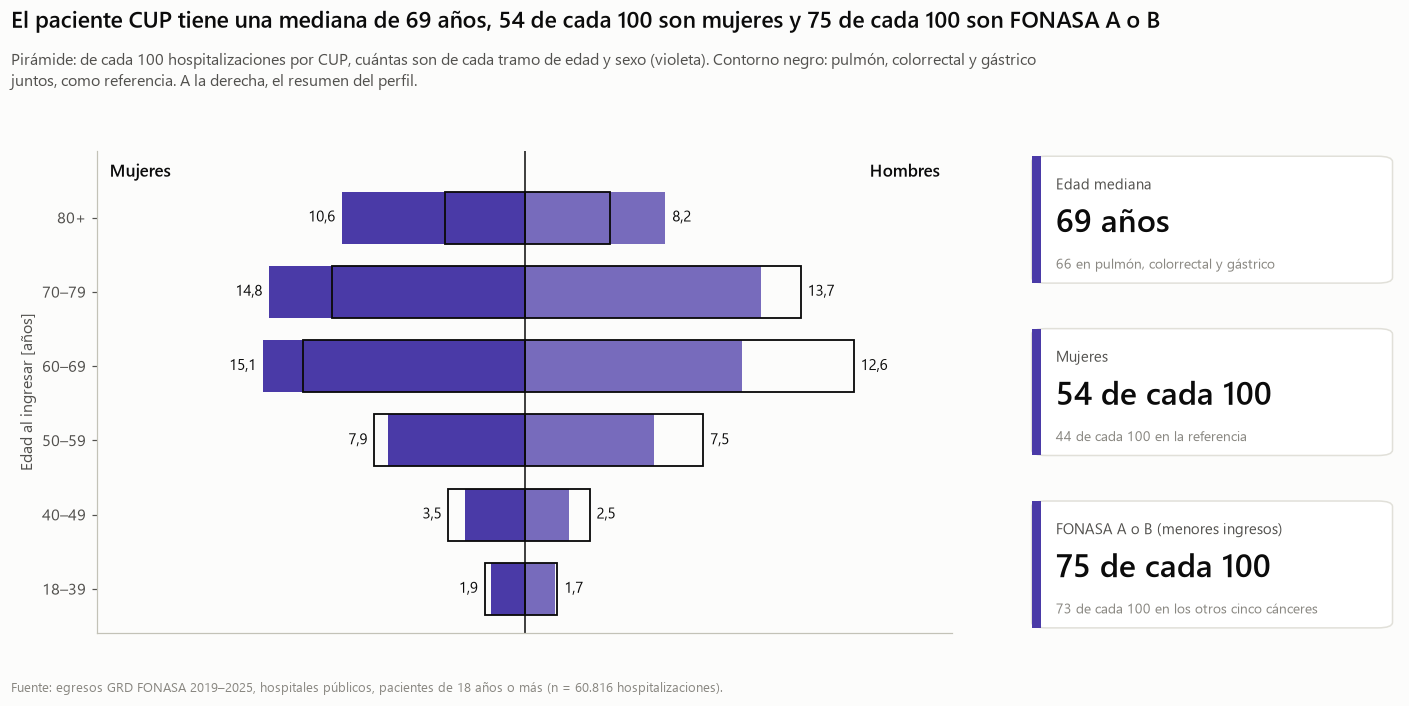

,CUP,Referencia
SEXO,,
HOMBRE,46.2,56.0
MUJER,53.8,44.0


In [12]:
TRAMOS_P = ['18–39', '40–49', '50–59', '60–69', '70–79', '80+']
df['TRAMO10'] = pd.cut(df['EDAD'], [18, 40, 50, 60, 70, 80, 200], right=False, labels=TRAMOS_P)


def piramide(d):
    return (pd.crosstab(d['TRAMO10'], d['SEXO'], normalize='all') * 100).reindex(TRAMOS_P).fillna(0)


cup = df[df.GRUPO == 'CUP']
ref = df[df.GRUPO.isin(['Pulmón', 'Colorrectal', 'Gástrico'])]
pc, pr = piramide(cup), piramide(ref)
med_cup, med_ref = cup['EDAD'].median(), ref['EDAD'].median()
muj = cup['MUJER'].mean() * 100
prev = (cup['PREVISION_G'].value_counts(normalize=True) * 100)
ab = prev.get('FONASA A', 0) + prev.get('FONASA B', 0)
ab_ref = (df[df.GRUPO != 'CUP']['PREVISION_G'].isin(['FONASA A', 'FONASA B']).mean() * 100)

figura = plt.figure(figsize=(13, 6.4))
rejilla = figura.add_gridspec(3, 2, width_ratios=[2.3, 1], hspace=0.25, wspace=0.12, left=0.07, right=0.98, bottom=0.1)
eje = figura.add_subplot(rejilla[:, 0])
y = np.arange(len(TRAMOS_P))
eje.barh(y, -pc['MUJER'], color=COLOR_CUP, height=0.7)
eje.barh(y, pc['HOMBRE'], color=COLOR_CUP, height=0.7, alpha=0.75)
eje.barh(y, -pr['MUJER'], height=0.7, fill=False, edgecolor=tinta, linewidth=1.2)
eje.barh(y, pr['HOMBRE'], height=0.7, fill=False, edgecolor=tinta, linewidth=1.2)
for yi, m, h, rm, rh in zip(y, pc['MUJER'], pc['HOMBRE'], pr['MUJER'], pr['HOMBRE']):
    eje.text(-max(m, rm) - 0.4, yi, coma(m), ha='right', va='center', fontsize=10, color=tinta)
    eje.text(max(h, rh) + 0.4, yi, coma(h), ha='left', va='center', fontsize=10, color=tinta)
lim = max(pc.max().max(), pr.max().max()) * 1.3
eje.set_xlim(-lim, lim)
eje.axvline(0, color=tinta, linewidth=1)
eje.set_yticks(y, TRAMOS_P)
eje.set_xticks([])
eje.set_ylabel('Edad al ingresar [años]')
eje.text(-lim * 0.97, len(TRAMOS_P) - 0.45, 'Mujeres', fontsize=11, fontweight='semibold', color=tinta)
eje.text(lim * 0.97, len(TRAMOS_P) - 0.45, 'Hombres', fontsize=11, fontweight='semibold', color=tinta, ha='right')
eje.set_ylim(-0.6, len(TRAMOS_P) - 0.1)
eje.grid(visible=False)
recuadro(figura.add_subplot(rejilla[0, 1]), 'Edad mediana', f'{med_cup:.0f} años',
         f'{med_ref:.0f} en pulmón, colorrectal y gástrico', COLOR_CUP)
recuadro(figura.add_subplot(rejilla[1, 1]), 'Mujeres', f'{de100(muj)} de cada 100',
         f'{de100(ref["MUJER"].mean() * 100)} de cada 100 en la referencia', COLOR_CUP)
recuadro(figura.add_subplot(rejilla[2, 1]), 'FONASA A o B (menores ingresos)', f'{de100(ab)} de cada 100',
         f'{de100(ab_ref)} de cada 100 en los otros cinco cánceres', COLOR_CUP)
poner_titulo(figura,
             f'El paciente CUP tiene una mediana de {med_cup:.0f} años, {de100(muj)} de cada 100 son mujeres y '
             f'{de100(ab)} de cada 100 son FONASA A o B',
             'Pirámide: de cada 100 hospitalizaciones por CUP, cuántas son de cada tramo de edad y sexo (violeta). Contorno negro: '
             'pulmón, colorrectal y gástrico\njuntos, como referencia. A la derecha, el resumen del perfil.', ajustar=False)
guardar(figura, 'P03_perfil_paciente')
pd.DataFrame({'CUP': pc.sum(), 'Referencia': pr.sum()}).round(1)

**Respuesta.** El paciente CUP es un adulto mayor: mediana de **69 años** (66 en pulmón, colorrectal y gástrico juntos), y casi 6 de cada 10 hospitalizaciones son de personas de 60 a 79 años. A diferencia de la referencia, hay más mujeres: **54 de cada 100**, frente a 44. Tres de cada cuatro (**75 de cada 100**) son FONASA A o B, los tramos de menores ingresos, una proporción parecida a la de los otros cánceres (73). Dentro de la red pública, el CUP no se concentra en un grupo socioeconómico distinto.

### P4. ¿A dónde se ha diseminado el cáncer y eso cambia el pronóstico?
**Cómo leer el mapa de calor:** cada casilla dice de cada 100 hospitalizaciones del grupo (columna) cuántas tienen codificada una metástasis en ese órgano (fila); más oscuro = más frecuente. Un egreso puede tener varios sitios, por eso las columnas no suman 100. A la derecha, solo para el CUP, cuántos mueren con y sin metástasis en cada sitio.

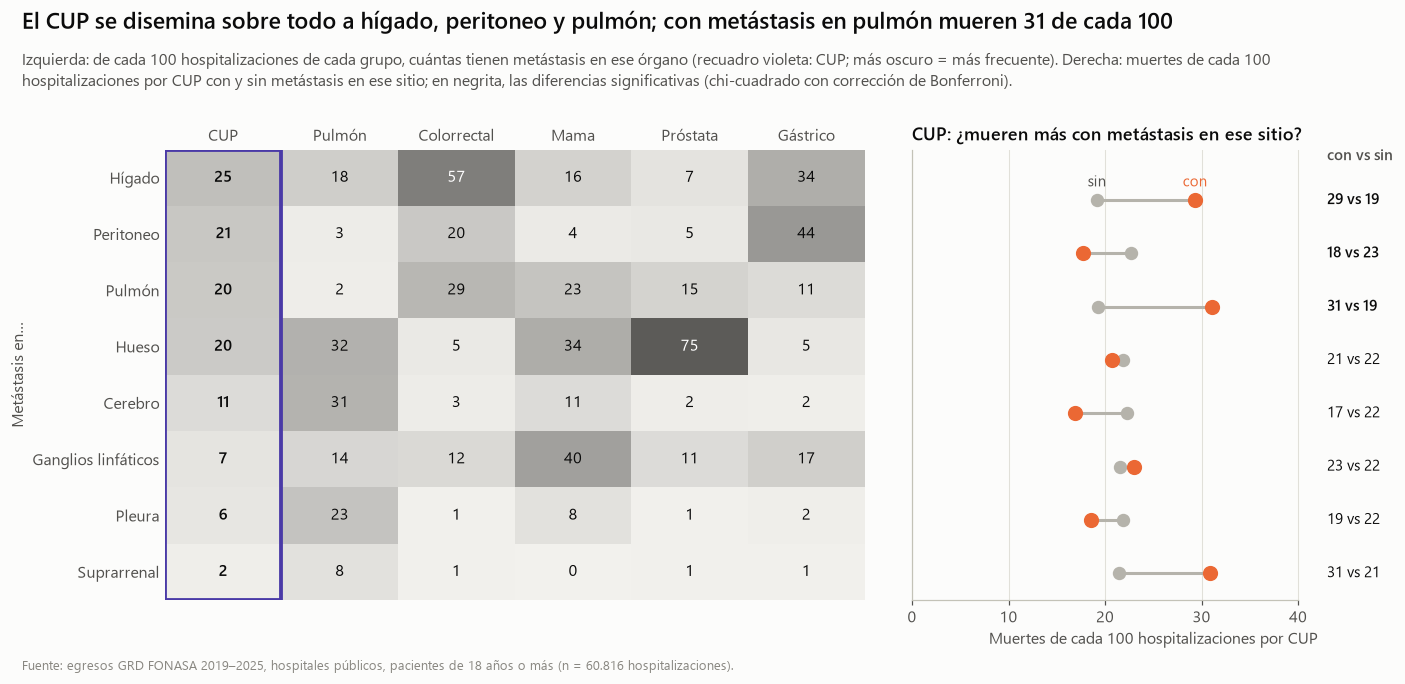

,n con el sitio,Mueren con (de cada 100),Mueren sin (de cada 100),p (Bonferroni)
Sitio,,,,
Hígado,973,29.291,19.136,0.000
Peritoneo,817,17.748,22.721,0.020
Pulmón,789,31.052,19.290,0.000
Hueso,761,20.762,21.899,1.000
Cerebro,431,16.937,22.267,0.108
Ganglios linfáticos,261,22.989,21.582,1.000
Pleura,243,18.519,21.887,1.000
Suprarrenal,81,30.864,21.481,0.468


In [13]:
cols_sitio = [f'MET_{s}' for s in SITIOS]
sitios = (df.groupby('GRUPO', observed=True)[cols_sitio].mean().T * 100)
sitios.index = list(SITIOS)
sitios = sitios.sort_values('CUP', ascending=False)
cup = df[df.GRUPO == 'CUP']
filas_m = []
for s in sitios.index:
    con, sin = cup[cup[f'MET_{s}'] == 1], cup[cup[f'MET_{s}'] == 0]
    p = stats.chi2_contingency(pd.crosstab(cup[f'MET_{s}'], cup['FALLECIDO']))[1]
    filas_m.append({'Sitio': s, 'n con el sitio': len(con), 'Mueren con (de cada 100)': con.FALLECIDO.mean() * 100,
                    'Mueren sin (de cada 100)': sin.FALLECIDO.mean() * 100, 'p (Bonferroni)': min(p * len(SITIOS), 1)})
mort_sitio = pd.DataFrame(filas_m).set_index('Sitio')

figura = plt.figure(figsize=(13, 6.2))
rejilla = figura.add_gridspec(1, 2, width_ratios=[1.45, 1], wspace=0.08, left=0.11, right=0.97, bottom=0.12)
eje = figura.add_subplot(rejilla[0, 0])
mapa = LinearSegmentedColormap.from_list('gris', ['#f3f2ee', '#52514e'])
eje.imshow(sitios[ORDEN].to_numpy(), cmap=mapa, aspect='auto', vmin=0, vmax=80)
for i in range(len(sitios)):
    for j, g in enumerate(ORDEN):
        v = sitios.iloc[i][g]
        eje.text(j, i, de100(v), ha='center', va='center', fontsize=10.5, color='white' if v > 45 else tinta,
                 fontweight='semibold' if g == 'CUP' else 'normal')
eje.add_patch(Rectangle((-0.5, -0.5), 1, len(sitios), fill=False, edgecolor=COLOR_CUP, linewidth=2.5))
eje.set_xticks(range(len(ORDEN)), ORDEN)
eje.xaxis.tick_top()
eje.set_yticks(range(len(sitios)), list(sitios.index))
eje.set_ylabel('Metástasis en…')
eje.grid(visible=False)
for lado in ['left', 'bottom']:
    eje.spines[lado].set_visible(False)
eje.tick_params(length=0)

eje = figura.add_subplot(rejilla[0, 1])
yy = np.arange(len(sitios))
m = mort_sitio.loc[sitios.index]
eje.hlines(yy, m['Mueren sin (de cada 100)'], m['Mueren con (de cada 100)'], color=gris_marca, linewidth=2)
eje.scatter(m['Mueren sin (de cada 100)'], yy, s=60, color=gris_marca, zorder=3, label='sin metástasis en ese sitio')
eje.scatter(m['Mueren con (de cada 100)'], yy, s=80, color=naranjo, zorder=3, label='con metástasis en ese sitio')
for yi, (s, r) in zip(yy, m.iterrows()):
    eje.text(43, yi, f'{de100(r["Mueren con (de cada 100)"])} vs {de100(r["Mueren sin (de cada 100)"])}', va='center',
             fontsize=10, color=tinta, fontweight='semibold' if r['p (Bonferroni)'] < 0.05 else 'normal')
eje.set_ylim(len(sitios) - 0.5, -0.95)
eje.set_yticks([])
eje.set_xlim(0, 50)
eje.set_xticks([0, 10, 20, 30, 40])
eje.spines['bottom'].set_bounds(0, 40)
eje.set_xlabel('Muertes de cada 100 hospitalizaciones por CUP')
eje.set_title('CUP: ¿mueren más con metástasis en ese sitio?')
eje.annotate('sin', (m['Mueren sin (de cada 100)'].iloc[0], 0), xytext=(0, 9), textcoords='offset points', ha='center',
            fontsize=9.5, color=gris_texto)
eje.annotate('con', (m['Mueren con (de cada 100)'].iloc[0], 0), xytext=(0, 9), textcoords='offset points', ha='center',
            fontsize=9.5, color=naranjo)
eje.text(43, -0.75, 'con vs sin', fontsize=10, color=gris_texto, fontweight='semibold')
eje.grid(axis='y', visible=False)
top3 = sitios.index[:3].str.lower().tolist()
peor = m['Mueren con (de cada 100)'][m['n con el sitio'] >= 100].idxmax()
poner_titulo(figura,
             f'El CUP se disemina sobre todo a {top3[0]}, {top3[1]} y {top3[2]}; con metástasis en {peor.lower()} mueren '
             f'{de100(m.loc[peor, "Mueren con (de cada 100)"])} de cada 100',
             'Izquierda: de cada 100 hospitalizaciones de cada grupo, cuántas tienen metástasis en ese órgano (recuadro violeta: CUP; más oscuro = más frecuente). '
             'Derecha: muertes de cada 100\nhospitalizaciones por CUP con y sin metástasis en ese sitio; en negrita, las '
             'diferencias significativas (chi-cuadrado con corrección de Bonferroni).', ajustar=False)
guardar(figura, 'P04_sitios_de_metastasis')
mort_sitio.round(3)

**Respuesta.** El CUP se disemina sobre todo a **hígado (25 de cada 100), peritoneo (21), pulmón (20) y hueso (20)**. Su patrón es más repartido que el de los cánceres de primario conocido, que tienen un destino dominante (próstata → hueso 75, colorrectal → hígado 57, gástrico → peritoneo 44).

El sitio sí cambia el pronóstico: con metástasis **pulmonar mueren 31 de cada 100** y con **hepática 29**, frente a 19 sin ellas (diferencias significativas). Con metástasis peritoneal mueren menos (18 frente a 23); una hipótesis es que muchas de esas hospitalizaciones son para procedimientos, como drenar líquido abdominal. Para el dashboard: el panel de sitios de metástasis debería mostrar también la mortalidad de cada sitio.

## 6. Bloque C — ¿Cómo lo atiende la red?
### P5. ¿Por dónde llega y quién lo atiende?
**Cómo leer el diagrama de flujo (Sankey):** cada banda es un grupo de hospitalizaciones por CUP y su grosor es proporcional a cuántas son. De izquierda a derecha: por dónde llegó el paciente, qué especialidad le dio el alta y cómo salió del hospital. En el notebook el gráfico es interactivo: al pasar el mouse se ve cada cifra.

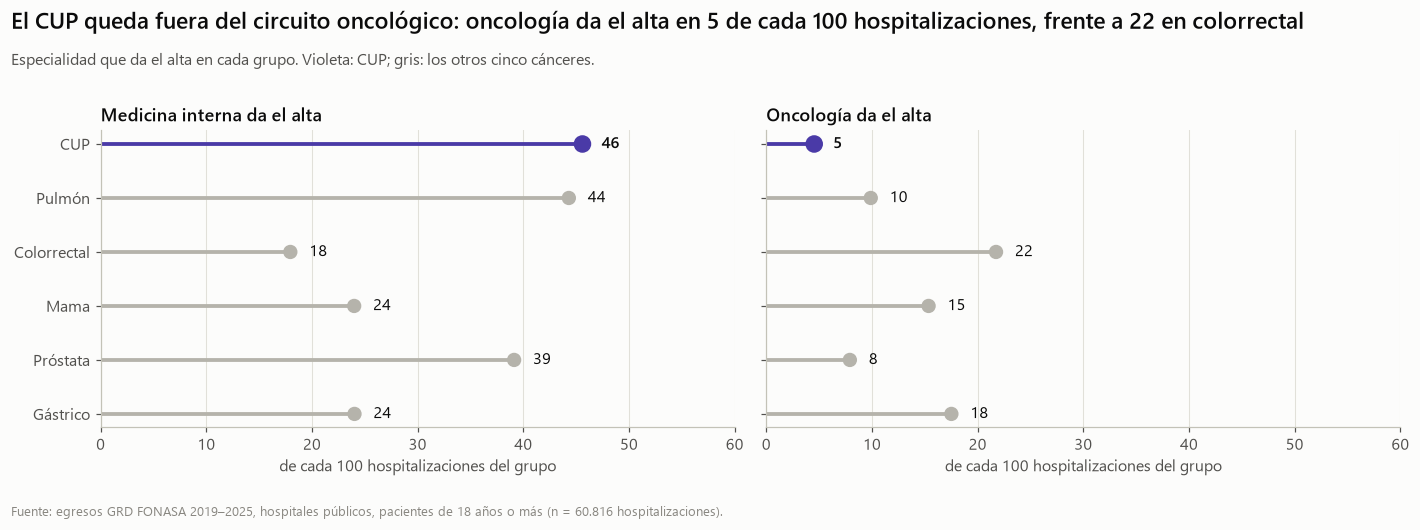

de cada 100
LLEGADA      Urgencia                             59.1
             Consulta de especialidad             20.5
             Otro hospital                        11.4
             Otra procedencia                      8.9
ESPECIALIDAD Medicina interna                     45.6
             Cirugía                              22.6
             Otra especialidad                    19.7
             Neurología / neurocirugía             7.6
             Oncología                             4.5
SALIDA       Alta a domicilio                     63.0
             Fallece                              21.7
             Hospitalización domiciliaria          8.1
             Derivado a otro centro                5.2
             Otra salida                           2.0

In [14]:
cup = df[df.GRUPO == 'CUP']
ETAPAS = ['LLEGADA', 'ESPECIALIDAD', 'SALIDA']
ORDEN_NODOS = {
    'LLEGADA': ['Urgencia', 'Consulta de especialidad', 'Otro hospital', 'Otra procedencia'],
    'ESPECIALIDAD': ['Medicina interna', 'Cirugía', 'Oncología', 'Neurología / neurocirugía', 'Otra especialidad'],
    'SALIDA': ['Alta a domicilio', 'Fallece', 'Hospitalización domiciliaria', 'Derivado a otro centro', 'Otra salida']}
n_cup = len(cup)
pct = {e: cup[e].value_counts(normalize=True) * 100 for e in ETAPAS}
urg, mi, onc = pct['LLEGADA']['Urgencia'], pct['ESPECIALIDAD']['Medicina interna'], pct['ESPECIALIDAD'].get('Oncología', 0)
titulo_p5 = (f'De cada 100 hospitalizaciones por CUP, {de100(urg)} llegan por urgencia, {de100(mi)} las atiende medicina '
             f'interna y solo {de100(onc)} oncología')

if HAY_PLOTLY:
    etiquetas, indice = [], {}
    for e in ETAPAS:
        for nodo in ORDEN_NODOS[e]:
            indice[(e, nodo)] = len(etiquetas)
            etiquetas.append(f'{nodo}  {de100(pct[e].get(nodo, 0))}')
    origen, destino, valor, color_link = [], [], [], []
    for a, b in [('LLEGADA', 'ESPECIALIDAD'), ('ESPECIALIDAD', 'SALIDA')]:
        for (x, z), n in cup.groupby([a, b]).size().items():
            origen.append(indice[(a, x)])
            destino.append(indice[(b, z)])
            valor.append(n)
            color_link.append('rgba(235,104,52,0.45)' if z == 'Fallece' else
                              'rgba(74,58,167,0.35)' if x == 'Oncología' or z == 'Oncología' else 'rgba(181,179,171,0.45)')
    color_nodo = [naranjo if 'Fallece' in t else COLOR_CUP if 'Oncología' in t else '#7d7b74' for t in etiquetas]
    fig = go.Figure(go.Sankey(
        arrangement='snap',
        node=dict(label=etiquetas, color=color_nodo, pad=18, thickness=16, line=dict(width=0),
                  hovertemplate='%{label}<br>%{value} hospitalizaciones<extra></extra>'),
        link=dict(source=origen, target=destino, value=valor, color=color_link,
                  hovertemplate='%{source.label} → %{target.label}<br>%{value} hospitalizaciones<extra></extra>')))
    plotly_base(fig, titulo_p5,
                f'{miles(n_cup)} hospitalizaciones por CUP. Columnas: por dónde llega → quién da el alta → cómo sale. '
                'Naranjo: fallece; violeta: oncología. Número = de cada 100.', alto=640)
    for x, texto in [(0.0, 'Llegada'), (0.5, 'Especialidad que da el alta'), (1.0, 'Salida')]:
        fig.add_annotation(text=f'<b>{texto}</b>', x=x, y=1.04, xref='paper', yref='paper', showarrow=False,
                           xanchor='left' if x == 0 else 'right' if x == 1 else 'center', font=dict(size=13, color=gris_texto))
    guardar_plotly(fig, 'P05_trayectoria_sankey')

# Comparación con los otros cánceres: ¿quién atiende?
esp_g = (pd.crosstab(df['GRUPO'], df['ESPECIALIDAD'], normalize='index') * 100)
figura, ejes = plt.subplots(1, 2, figsize=(13, 4.8), sharey=True)
for eje, (cat, nombre) in zip(ejes, [('Medicina interna', 'Medicina interna da el alta'),
                                     ('Oncología', 'Oncología da el alta')]):
    yv = puntos_por_grupo(eje, esp_g[cat], ORDEN, xmax=60)
    eje.set_title(nombre)
    eje.set_xlabel('de cada 100 hospitalizaciones del grupo')
ejes[0].set_yticks(yv, ORDEN)
poner_titulo(figura,
             f'El CUP queda fuera del circuito oncológico: oncología da el alta en {de100(onc)} de cada 100 hospitalizaciones, '
             f'frente a {de100(esp_g.loc["Colorrectal", "Oncología"])} en colorrectal',
             'Especialidad que da el alta en cada grupo. Violeta: CUP; gris: los otros cinco cánceres.')
guardar(figura, 'P05b_especialidad')
pd.concat({e: pct[e].round(1) for e in ETAPAS}).to_frame('de cada 100')

**Respuesta.** El CUP entra por la puerta de urgencia: **59 de cada 100** llegan desde un servicio de urgencia (81 de cada 100 quedan registrados como ingreso de urgencia) y solo 21 desde una consulta de especialidad. Dentro del hospital lo atiende sobre todo **medicina interna (46 de cada 100)**, y **oncología da el alta en apenas 5 de cada 100**, la cifra más baja de los seis grupos (colorrectal 22, gástrico 18, mama 15).

El CUP se maneja fuera del circuito oncológico, probablemente porque sin primario no hay un equipo de órgano que lo reciba. El diagrama muestra además que la mayor parte de las muertes (bandas naranjas) ocurre en medicina interna: 6 de cada 10 pacientes CUP que mueren en el hospital fallecen a su cargo.

### P6. ¿Cómo sale del hospital y vuelve a hospitalizarse?
*Reingreso a 30 días* = otra hospitalización por cualquiera de estos cánceres dentro de los 30 días posteriores al alta (solo para quienes salen vivos; se excluyen las altas de diciembre de 2020 y de diciembre de 2025, que no se pueden seguir).

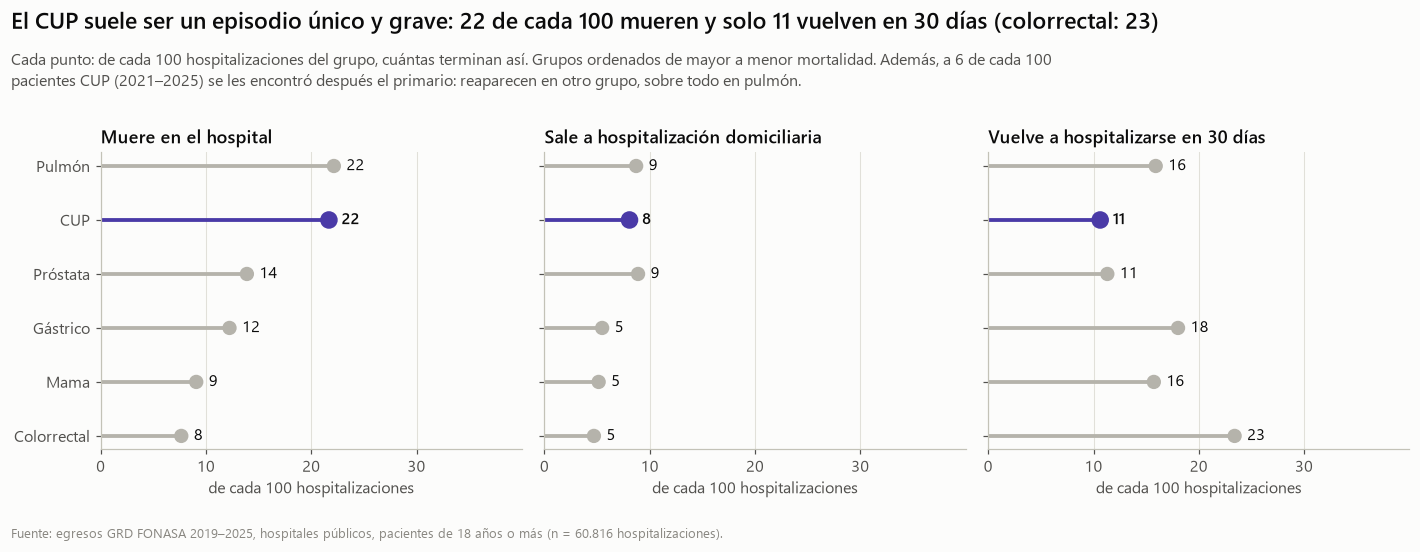

Pacientes CUP 2021-2025: 2524; con primario hallado después: 155 (6.1 %): {'Pulmón': 71, 'Colorrectal': 29, 'Gástrico': 21, 'Mama': 19, 'Próstata': 15}


,egresos_por_paciente,mueren_de_cada_100
GRUPO,,
CUP,1.11,23.42
Pulmón,1.27,29.59
Colorrectal,1.70,13.96
Mama,1.45,14.15
Próstata,1.35,18.35
Gástrico,1.39,17.87


In [15]:
ORDEN_MORT = df.groupby('GRUPO', observed=True)['FALLECIDO'].mean().sort_values(ascending=False).index.tolist()
condiciones = [('FALLECIDO', 'Muere en el hospital'), ('HOSP_DOM', 'Sale a hospitalización domiciliaria'),
               ('REINGRESO30', 'Vuelve a hospitalizarse en 30 días')]
salida = df.groupby('GRUPO', observed=True)[[v for v, _ in condiciones]].mean() * 100
figura, ejes = plt.subplots(1, 3, figsize=(13, 5), sharey=True)
for eje, (v, nombre) in zip(ejes, condiciones):
    yv = puntos_por_grupo(eje, salida[v], ORDEN_MORT, xmax=40, sep=1.2)
    eje.set_title(nombre)
    eje.set_xlabel('de cada 100 hospitalizaciones')
ejes[0].set_yticks(yv, ORDEN_MORT)
for eje in ejes:
    eje.set_xticks([0, 10, 20, 30])
# Seguimiento por paciente (2021-2025, ID consistente)
seg = df[df.ANIO >= 2021]
por_pac = seg.groupby(['GRUPO', 'CIP_ENCRIPTADO'], observed=True).agg(n=('FALLECIDO', 'size'), muere=('FALLECIDO', 'max'))
pacientes = por_pac.groupby('GRUPO', observed=True).agg(egresos_por_paciente=('n', 'mean'), mueren_de_cada_100=('muere', 'mean'))
pacientes['mueren_de_cada_100'] *= 100
cup_pac = seg[seg.GRUPO == 'CUP'].groupby('CIP_ENCRIPTADO')['FECHA_INGRESO'].min()
otros = seg[seg.GRUPO != 'CUP'][['CIP_ENCRIPTADO', 'FECHA_INGRESO', 'GRUPO']].merge(cup_pac.rename('primer_cup'),
                                                                                  left_on='CIP_ENCRIPTADO', right_index=True)
despues = otros[otros.FECHA_INGRESO > otros.primer_cup].drop_duplicates('CIP_ENCRIPTADO')
pct_hallado = len(despues) / len(cup_pac) * 100
rc = salida.loc['Colorrectal', 'REINGRESO30']
poner_titulo(figura,
             f'El CUP suele ser un episodio único y grave: {de100(salida.loc["CUP", "FALLECIDO"])} de cada 100 mueren y solo '
             f'{de100(salida.loc["CUP", "REINGRESO30"])} vuelven en 30 días (colorrectal: {de100(rc)})',
             'Cada punto: de cada 100 hospitalizaciones del grupo, cuántas terminan así. Grupos ordenados de mayor a menor mortalidad. '
             f'Además, a {de100(pct_hallado)} de cada 100\npacientes CUP (2021–2025) se les encontró después el primario: '
             f'reaparecen en otro grupo, sobre todo en pulmón.')
guardar(figura, 'P06_salida_y_reingreso')
print(f'Pacientes CUP 2021-2025: {len(cup_pac)}; con primario hallado después: {len(despues)} '
      f'({pct_hallado:.1f} %): {despues.GRUPO.astype(str).value_counts().to_dict()}')
pacientes.round(2)

**Respuesta.** El CUP suele ser un episodio único y grave. **22 de cada 100** hospitalizaciones terminan en muerte (igual que pulmón) y, de quienes salen vivos, solo **11 de cada 100** vuelven a hospitalizarse por cáncer dentro de 30 días, la mitad que en colorrectal (23). Por paciente (2021–2025) hay 1,1 hospitalizaciones, frente a 1,7 en colorrectal, y 23 de cada 100 pacientes CUP mueren en alguna de ellas. 8 de cada 100 salen a hospitalización domiciliaria, como en pulmón y próstata (9).

El bajo reingreso no significa que les vaya bien: una explicación probable es que muchos fallecen fuera del hospital o pasan a cuidados paliativos, algo que el GRD no registra. Además, **a 6 de cada 100 pacientes CUP se les encontró después el primario** (reaparecen en otro grupo, casi la mitad en pulmón): el C80.0 a veces es un diagnóstico provisorio.

### P7. ¿Cuántos recursos usa?
**Cómo leer el gráfico de estadía.** El **punto** es la estadía mediana: la mitad de las hospitalizaciones dura menos y la otra mitad, más. La **barra** cubre la mitad central (percentiles 25 a 75). Se usa la mediana y no el promedio porque unas pocas estadías muy largas (sección 3.6) inflarían el promedio.

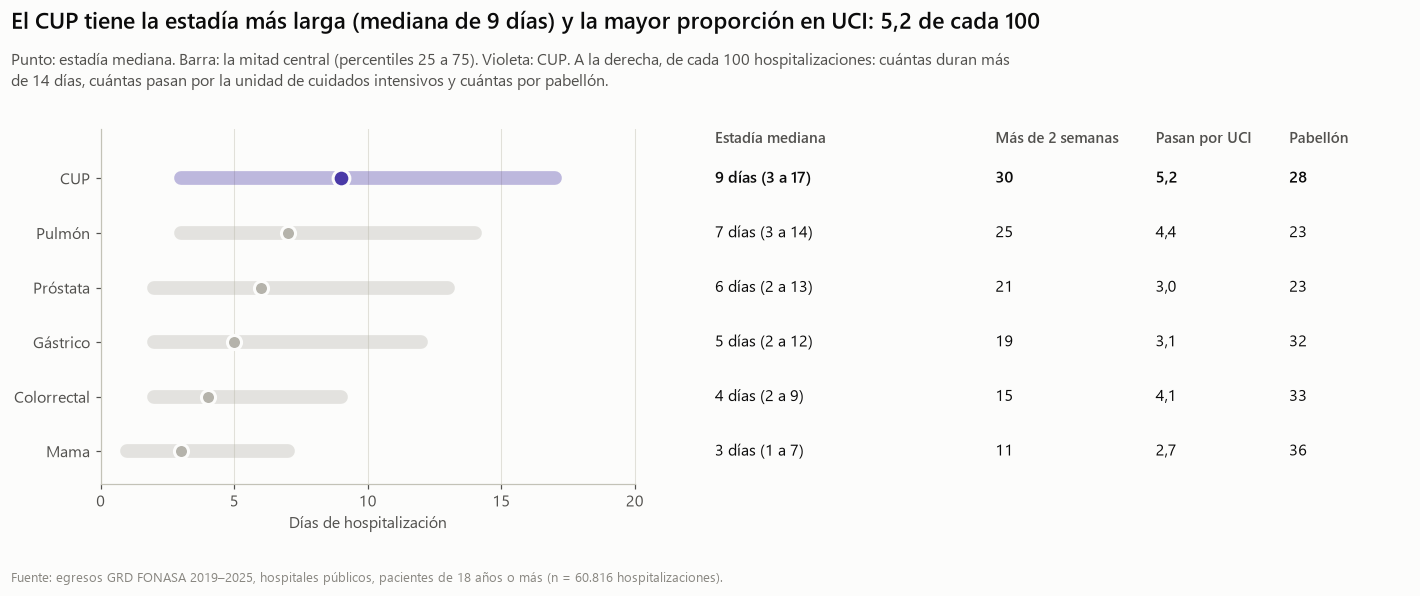

,p25,mediana,p75,mas_2_semanas,uci,pabellon,peso
GRUPO,,,,,,,
CUP,3.0,9.0,17.0,29.60,5.25,27.67,1.39
Pulmón,3.0,7.0,14.0,24.95,4.36,22.81,1.34
Colorrectal,2.0,4.0,9.0,14.93,4.14,33.19,1.49
Mama,1.0,3.0,7.0,11.31,2.69,36.21,1.14
Próstata,2.0,6.0,13.0,21.11,3.01,23.07,1.21
Gástrico,2.0,5.0,12.0,19.49,3.14,31.90,1.38


In [16]:
estadia = df.groupby('GRUPO', observed=True).agg(
    p25=('DIAS_ESTADA', lambda s: s.quantile(.25)), mediana=('DIAS_ESTADA', 'median'),
    p75=('DIAS_ESTADA', lambda s: s.quantile(.75)), mas_2_semanas=('DIAS_ESTADA', lambda s: (s > 14).mean() * 100),
    uci=('UCI', lambda s: s.mean() * 100), pabellon=('USO_PABELLON', lambda s: s.mean() * 100),
    peso=('PESO_GRD', 'mean'))
filas_e = estadia.sort_values(['mediana', 'p75'], ascending=False).index.tolist()
cup_e = estadia.loc['CUP']
y = np.arange(len(filas_e))[::-1]
figura, eje = plt.subplots(figsize=(13, 5.4))
for yi, g in zip(y, filas_e):
    r = estadia.loc[g]
    eje.hlines(yi, r.p25, r.p75, color=color_grupo(g), linewidth=9, alpha=0.35, capstyle='round')
    eje.scatter(r.mediana, yi, s=120 if g == 'CUP' else 85, color=color_grupo(g), edgecolor='#fcfcfb', linewidth=2, zorder=3)
    peso_txt = 'semibold' if g == 'CUP' else 'normal'
    eje.text(23, yi, f'{r.mediana:.0f} días ({r.p25:.0f} a {r.p75:.0f})', va='center', fontsize=10.5, color=tinta, fontweight=peso_txt)
    eje.text(33.5, yi, de100(r.mas_2_semanas), va='center', fontsize=10.5, color=tinta, fontweight=peso_txt)
    eje.text(39.5, yi, coma(r.uci), va='center', fontsize=10.5, color=tinta, fontweight=peso_txt)
    eje.text(44.5, yi, de100(r.pabellon), va='center', fontsize=10.5, color=tinta, fontweight=peso_txt)
for x, t in [(23, 'Estadía mediana'), (33.5, 'Más de 2 semanas'), (39.5, 'Pasan por UCI'), (44.5, 'Pabellón')]:
    eje.text(x, len(filas_e) - 0.35, t, fontsize=10, color=gris_texto, fontweight='semibold')
eje.set_xlim(0, 49)
eje.set_ylim(-0.6, len(filas_e) - 0.1)
eje.set_xticks([0, 5, 10, 15, 20])
eje.spines['bottom'].set_bounds(0, 20)
eje.set_xlabel('Días de hospitalización')
eje.xaxis.set_label_coords(10 / 49, -0.09)
eje.set_yticks(y, filas_e)
eje.grid(axis='y', visible=False)
es_mayor = cup_e['mediana'] == estadia['mediana'].max()
uci_mayor = cup_e['uci'] == estadia['uci'].max()
poner_titulo(figura,
             (f'El CUP tiene la estadía más larga (mediana de {cup_e.mediana:.0f} días)' if es_mayor
              else f'La estadía mediana del CUP es de {cup_e.mediana:.0f} días')
             + (f' y la mayor proporción en UCI: {coma(cup_e.uci)} de cada 100' if uci_mayor
                else f'; {coma(cup_e.uci)} de cada 100 pasan por UCI'),
             'Punto: estadía mediana. Barra: la mitad central (percentiles 25 a 75). Violeta: CUP. A la derecha, de cada 100 '
             'hospitalizaciones: cuántas duran más\nde 14 días, cuántas pasan por la unidad de cuidados intensivos y cuántas por pabellón.')
guardar(figura, 'P07_estadia_y_recursos')
estadia.round(2)

**Respuesta.** El CUP es el grupo que más días de cama usa por hospitalización: mediana de **9 días** (la mitad central, de 3 a 17), frente a 3 en mama y 4 en colorrectal, y **30 de cada 100** duran más de dos semanas. También es el que más pasa por **UCI (5,2 de cada 100)**. En cambio usa menos pabellón (28 de cada 100) que los cánceres que se operan (mama 36, colorrectal 33, gástrico 32): sus días se van en estudio y manejo médico, no en cirugía. Su peso GRD medio (1,39) es intermedio entre los seis grupos.

## 7. Bloque D — ¿Le va peor al CUP que a los cánceres metastásicos de primario conocido?
### P8. ¿El CUP muere más?

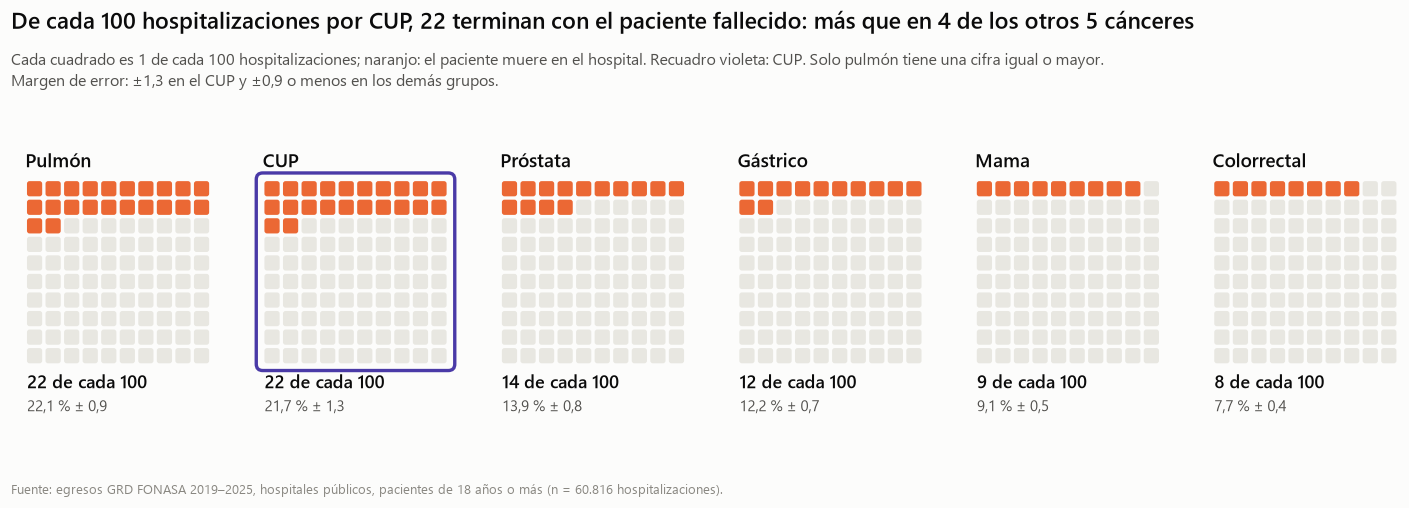

,Variable,Prueba,Estadístico,gl,p
0,Mortalidad,Chi-cuadrado,1654.9,5,0.000000e+00
1,Severidad 3,Chi-cuadrado,2807.1,5,0.000000e+00
2,Ingreso urgencia,Chi-cuadrado,4428.6,5,0.000000e+00
3,Uso de pabellón,Chi-cuadrado,699.2,5,7.374457e-149
4,Paso por UCI,Chi-cuadrado,100.8,5,3.586114e-20
5,Estancia,Kruskal-Wallis,3431.9,5,0.000000e+00
6,Peso GRD,Kruskal-Wallis,2006.1,5,0.000000e+00
7,Edad,Kruskal-Wallis,6340.2,5,0.000000e+00


,Mortalidad: dif. (pp),Mortalidad: p,Severidad 3: dif. (pp),Severidad 3: p,Urgencia: dif. (pp),Urgencia: p,Estancia: mediana CUP vs grupo,Estancia: p
Grupo,,,,,,,,
Pulmón,-0.500000,1,-0.400000,1,6.400000,4.7e-14,9 vs 7,1.08e-12
Colorrectal,14.000000,4.46e-158,23.200000,7.49e-179,31.800000,1.1e-290,9 vs 4,5.18e-163
Mama,12.600000,1.09e-97,25.900000,9.71e-203,35.300000,0,9 vs 3,0
Próstata,7.800000,2.86e-24,5.400000,5.98e-07,2.500000,0.0122,9 vs 6,5.42e-36
Gástrico,9.400000,4.62e-41,15.000000,5.99e-55,22.500000,1.26e-130,9 vs 5,2.25e-74


In [17]:
mort = df.groupby('GRUPO', observed=True)['FALLECIDO'].agg(['sum', 'size'])
mort['pct'] = mort['sum'] / mort['size'] * 100
lo, hi = ic_prop(mort['sum'], mort['size'])
mort['margen'] = (hi - lo) / 2
cup_m, otros_m = mort.loc['CUP'], mort.drop('CUP')
n_menos = int((otros_m['pct'] < cup_m['pct']).sum())
iguales_o_mas = otros_m[otros_m['pct'] >= cup_m['pct']].index.tolist()
figura = plt.figure(figsize=(13, 4.6))
rejilla = figura.add_gridspec(1, 6, wspace=0.28, left=0.02, right=0.98, bottom=0.2)
poner_titulo(figura,
             f'De cada 100 hospitalizaciones por CUP, {de100(cup_m.pct)} terminan con el paciente fallecido: '
             f'más que en {n_menos} de los otros 5 cánceres',
             'Cada cuadrado es 1 de cada 100 hospitalizaciones; naranjo: el paciente muere en el hospital. Recuadro violeta: CUP. '
             + (f'Solo {" y ".join(g.lower() for g in iguales_o_mas)} tiene una cifra igual o mayor.' if iguales_o_mas else '')
             + f'\nMargen de error: ±{coma(cup_m.margen)} en el CUP y ±{coma(otros_m.margen.max())} o menos en los demás grupos.',
             ajustar=False)
for k, g in enumerate(ORDEN_MORT):
    eje = figura.add_subplot(rejilla[0, k])
    n = int(round(mort.loc[g, 'pct']))
    matriz_iconos(eje, [n, 100 - n], [naranjo, fondo_icono])
    eje.set_title(g, fontsize=12.5, pad=8)
    eje.text(0.1, -9.5, f'{n} de cada 100', fontsize=12, fontweight='semibold', color=tinta, va='top')
    eje.text(0.1, -10.9, f'{coma(mort.loc[g, "pct"])} % ± {coma(mort.loc[g, "margen"])}', fontsize=9.5, color=gris_texto, va='top')
    if g == 'CUP':
        eje.add_patch(FancyBboxPatch((-0.35, -9.3), 10.7, 10.65, boxstyle='round,pad=0,rounding_size=0.35',
                                     fill=False, edgecolor=COLOR_CUP, linewidth=2.2, clip_on=False))
guardar(figura, 'P08_mortalidad_de_cada_100')

# Pruebas: diferencias entre los 6 grupos y CUP contra cada grupo (Bonferroni, 5 comparaciones)
filas = []
for v, nombre in [('FALLECIDO', 'Mortalidad'), ('SEV3', 'Severidad 3'), ('URGENCIA', 'Ingreso urgencia'),
                  ('USO_PABELLON', 'Uso de pabellón'), ('UCI', 'Paso por UCI')]:
    chi2, p, gl = stats.chi2_contingency(pd.crosstab(df['GRUPO'], df[v]))[:3]
    filas.append([nombre, 'Chi-cuadrado', round(chi2, 1), gl, p])
for v, nombre in [('DIAS_ESTADA', 'Estancia'), ('PESO_GRD', 'Peso GRD'), ('EDAD', 'Edad')]:
    h, p = stats.kruskal(*[d[v].dropna() for _, d in df.groupby('GRUPO', observed=True)])
    filas.append([nombre, 'Kruskal-Wallis', round(h, 1), 5, p])
display(pd.DataFrame(filas, columns=['Variable', 'Prueba', 'Estadístico', 'gl', 'p']))

cup = df[df.GRUPO == 'CUP']
filas = []
for g in ORDEN[1:]:
    otro = df[df.GRUPO == g]
    fila = {'Grupo': g}
    for v, nombre in [('FALLECIDO', 'Mortalidad'), ('SEV3', 'Severidad 3'), ('URGENCIA', 'Urgencia')]:
        par = pd.concat([cup, otro])
        p = stats.chi2_contingency(pd.crosstab(par['GRUPO'].astype(str), par[v]))[1]
        fila[f'{nombre}: dif. (pp)'] = round((cup[v].mean() - otro[v].mean()) * 100, 1)
        fila[f'{nombre}: p'] = min(p * 5, 1)
    p = stats.mannwhitneyu(cup['DIAS_ESTADA'], otro['DIAS_ESTADA'])[1]
    fila['Estancia: mediana CUP vs grupo'] = f"{cup['DIAS_ESTADA'].median():.0f} vs {otro['DIAS_ESTADA'].median():.0f}"
    fila['Estancia: p'] = min(p * 5, 1)
    filas.append(fila)
comparacion = pd.DataFrame(filas).set_index('Grupo')
comparacion.style.format({c: '{:.3g}' for c in comparacion.columns if c.endswith(': p')})

**Respuesta.** Sí. Mueren **22 de cada 100** hospitalizados por CUP: más del doble que en mama (9) y casi el triple que en colorrectal (8). Solo pulmón tiene la misma cifra (22). Las pruebas chi-cuadrado y Kruskal-Wallis muestran que todas las variables difieren entre los seis grupos (p < 0,001). En la comparación del CUP contra cada grupo (con corrección de Bonferroni), el CUP tiene más mortalidad, más gravedad y estancias más largas que colorrectal, mama, próstata y gástrico. Frente a pulmón, la mortalidad y la gravedad no difieren, pero el CUP ingresa más por urgencia (6 puntos más) y se queda más días (9 frente a 7).

### P9. ¿Se explica porque llega más grave o más viejo?
Si el CUP muriera más solo por llegar más grave o más viejo, a igual gravedad o edad su línea se juntaría con las grises. Luego una regresión logística compara la mortalidad **a igual edad, sexo, gravedad y tipo de ingreso** a la vez. La severidad 0 (GRD sin nivel de severidad, casi sin fallecidos) se agrupa con la 1 como "baja".

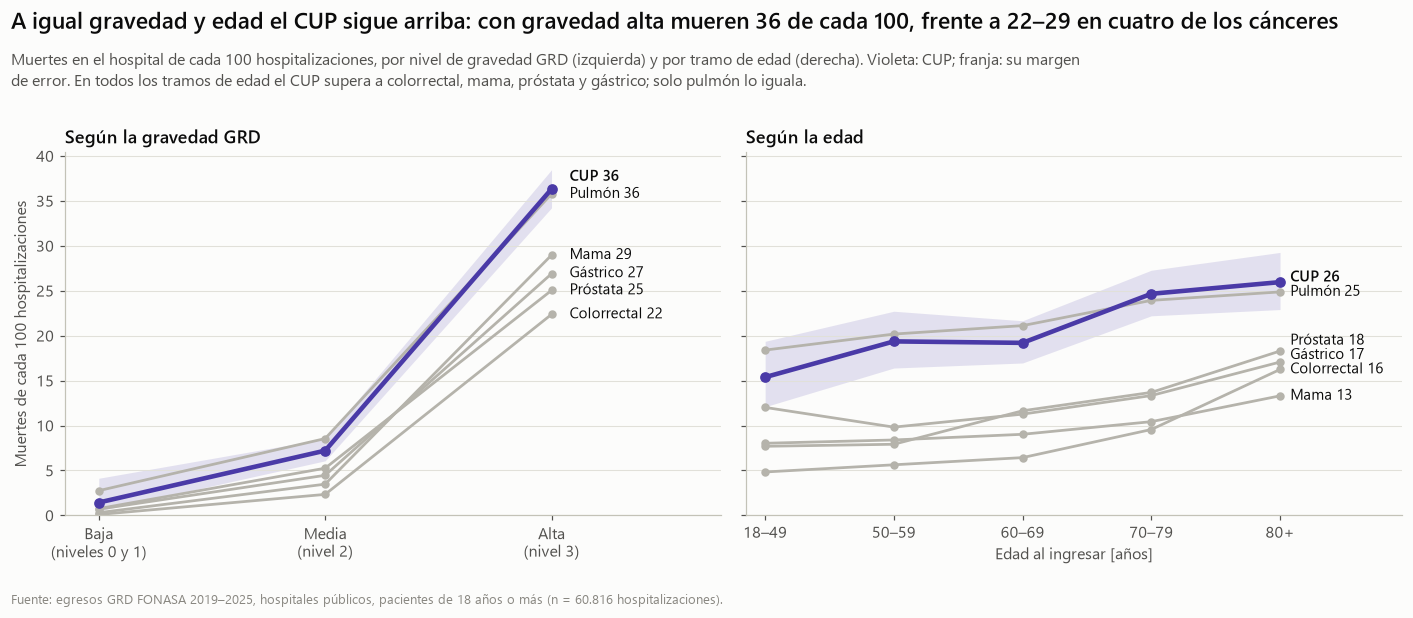

In [18]:
df['SEV_CAT'] = df['SEVERIDAD'].clip(lower=1)
NIVELES = {1: 'Baja\n(niveles 0 y 1)', 2: 'Media\n(nivel 2)', 3: 'Alta\n(nivel 3)'}
TRAMOS = ['18–49', '50–59', '60–69', '70–79', '80+']
df['TRAMO_EDAD'] = pd.cut(df['EDAD'], [18, 50, 60, 70, 80, 200], right=False, labels=TRAMOS)
N_MIN = 30

figura, ejes = plt.subplots(1, 2, figsize=(13, 5.6), sharey=True)
cuenta = df.groupby(['SEV_CAT', 'GRUPO'], observed=True)['FALLECIDO'].agg(['sum', 'size'])
grav = (cuenta['sum'] / cuenta['size'] * 100).unstack()
lo_g, hi_g = ic_prop(cuenta.xs('CUP', level='GRUPO')['sum'], cuenta.xs('CUP', level='GRUPO')['size'])
xs = np.arange(len(NIVELES))
lineas_por_grupo(ejes[0], xs, grav.reset_index(drop=True), banda=(lo_g, hi_g))
rotular_finales(ejes[0], xs[-1], grav.loc[3].to_dict(), 1.9, lambda g, v: f'{g} {de100(v)}')
ejes[0].set_xticks(xs, list(NIVELES.values()))
ejes[0].set_xlim(-0.15, xs[-1] + 0.75)
ejes[0].set_title('Según la gravedad GRD')
ejes[0].set_ylabel('Muertes de cada 100 hospitalizaciones')

cuenta_e = df.groupby(['TRAMO_EDAD', 'GRUPO'], observed=True)['FALLECIDO'].agg(['sum', 'size'])
por_edad = (cuenta_e['sum'] / cuenta_e['size'] * 100).where(cuenta_e['size'] >= N_MIN).unstack()
lo_e, hi_e = ic_prop(cuenta_e.xs('CUP', level='GRUPO')['sum'], cuenta_e.xs('CUP', level='GRUPO')['size'])
xe = np.arange(len(TRAMOS))
lineas_por_grupo(ejes[1], xe, por_edad.reset_index(drop=True), banda=(lo_e, hi_e))
rotular_finales(ejes[1], xe[-1], por_edad.iloc[-1].to_dict(), 1.6, lambda g, v: f'{g} {de100(v)}')
ejes[1].set_xticks(xe, TRAMOS)
ejes[1].set_xlim(-0.15, xe[-1] + 0.95)
ejes[1].set_xlabel('Edad al ingresar [años]')
ejes[1].set_title('Según la edad')
for eje in ejes:
    eje.set_ylim(0, None)
    eje.grid(axis='x', visible=False)
cuatro_g = grav.loc[3].drop(['CUP', 'Pulmón'])
cuatro_e = por_edad.drop(columns=['CUP', 'Pulmón'])
sobre_todos = bool((por_edad['CUP'] > cuatro_e.max(axis=1)).all())
poner_titulo(figura,
             f'A igual gravedad y edad el CUP sigue arriba: con gravedad alta mueren {de100(grav.loc[3, "CUP"])} de cada 100, '
             f'frente a {de100(cuatro_g.min())}–{de100(cuatro_g.max())} en cuatro de los cánceres',
             'Muertes en el hospital de cada 100 hospitalizaciones, por nivel de gravedad GRD (izquierda) y por tramo de edad (derecha). '
             'Violeta: CUP; franja: su margen\nde error. ' + ('En todos los tramos de edad el CUP supera a colorrectal, mama, próstata y gástrico; '
             'solo pulmón lo iguala.' if sobre_todos else 'Solo pulmón lo iguala.'))
guardar(figura, 'P09a_gravedad_y_edad')

In [19]:
try:
    import statsmodels.api as sm
    import statsmodels.formula.api as smf
    m = df.dropna(subset=['EDAD', 'SEVERIDAD']).copy()
    m['GRUPO'] = pd.Categorical(m['GRUPO'].astype(str), ORDEN)
    m['SEV_CAT'] = m['SEVERIDAD'].clip(lower=1).astype(int)
    FORMULA = 'FALLECIDO ~ C(GRUPO) + EDAD + MUJER + C(SEV_CAT) + URGENCIA'
    modelo = smf.logit(FORMULA, data=m).fit(disp=0)
    ic = modelo.conf_int()
    ors = pd.DataFrame({'OR': np.exp(modelo.params), 'IC95% inf': np.exp(ic[0]), 'IC95% sup': np.exp(ic[1]),
                        'p': modelo.pvalues}).round(3)
    display(ors.drop(index='Intercept'))
except ImportError:
    print('statsmodels no está instalado: ejecutar  pip install statsmodels  y volver a correr esta celda.')

,OR,IC95% inf,IC95% sup,p
C(GRUPO)[T.Pulmón],1.124,1.017,1.242,0.022
C(GRUPO)[T.Colorrectal],0.549,0.497,0.607,0.000
C(GRUPO)[T.Mama],0.785,0.702,0.879,0.000
C(GRUPO)[T.Próstata],0.560,0.498,0.629,0.000
C(GRUPO)[T.Gástrico],0.761,0.681,0.849,0.000
C(SEV_CAT)[T.2],3.705,2.647,5.187,0.000
C(SEV_CAT)[T.3],21.811,15.604,30.487,0.000
EDAD,1.008,1.006,1.011,0.000
MUJER,0.978,0.917,1.043,0.495
URGENCIA,5.635,5.078,6.253,0.000


**Cómo leer la mortalidad ajustada.** Los OR de la tabla son exactos pero difíciles de leer. El gráfico los traduce a muertes de cada 100: con el modelo se calcula cuántos morirían si **todos** los pacientes del estudio, con sus mismas edades, sexos, gravedades y tipos de ingreso, tuvieran cada diagnóstico (estandarización por el modelo). El margen de error se obtiene por *bootstrap*: se repite el cálculo en 200 remuestras al azar de los mismos datos.

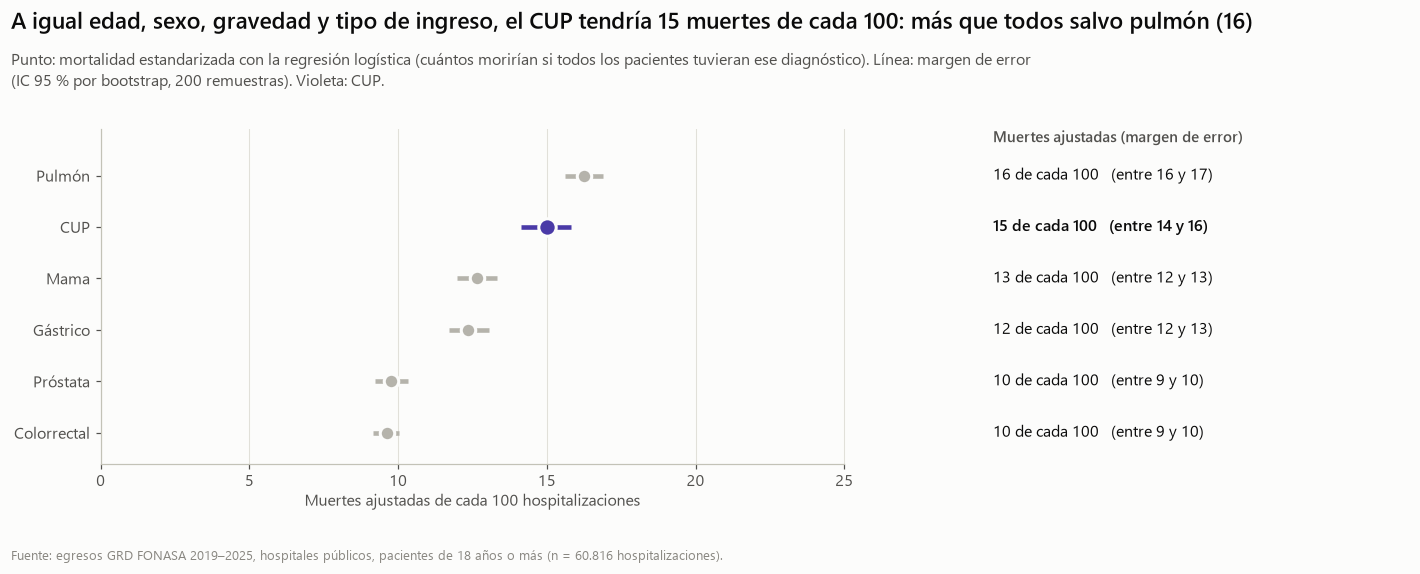

,ajustada,inf,sup
CUP,15.0,14.1,15.8
Pulmón,16.2,15.6,16.9
Colorrectal,9.6,9.2,10.0
Mama,12.6,12.0,13.3
Próstata,9.8,9.2,10.3
Gástrico,12.3,11.7,13.1


In [20]:
if 'modelo' in globals():
    X = modelo.model.exog
    y_m = modelo.model.endog
    nombres = modelo.model.exog_names
    col_g = {g: nombres.index(f'C(GRUPO)[T.{g}]') for g in ORDEN[1:]}

    def mortalidad_ajustada(Xm, params):
        """Muertes de cada 100 si todos los pacientes de Xm tuvieran cada diagnóstico."""
        resultado = {}
        for g in ORDEN:
            Xc = Xm.copy()
            Xc[:, list(col_g.values())] = 0
            if g != 'CUP':
                Xc[:, col_g[g]] = 1
            resultado[g] = (1 / (1 + np.exp(-Xc @ params))).mean() * 100
        return pd.Series(resultado)

    ajustada = mortalidad_ajustada(X, modelo.params.to_numpy())
    N_BOOT = 200
    rng = np.random.default_rng(2026)
    remuestras = []
    for _ in range(N_BOOT):
        idx = rng.integers(0, len(y_m), len(y_m))
        ajuste = sm.Logit(y_m[idx], X[idx]).fit(start_params=modelo.params.to_numpy(), disp=0)
        remuestras.append(mortalidad_ajustada(X[idx], ajuste.params))
    remuestras = pd.DataFrame(remuestras)
    lo_aj, hi_aj = remuestras.quantile(.025), remuestras.quantile(.975)

    filas_a = ajustada.sort_values(ascending=False).index.tolist()
    mayores = [g for g in filas_a if ajustada[g] > ajustada['CUP']]
    y = np.arange(len(filas_a))[::-1]
    figura, eje = plt.subplots(figsize=(13, 5.2))
    for yi, g in zip(y, filas_a):
        es_cup = g == 'CUP'
        eje.hlines(yi, lo_aj[g], hi_aj[g], color=color_grupo(g), linewidth=3)
        eje.scatter(ajustada[g], yi, s=130 if es_cup else 90, color=color_grupo(g), edgecolor='#fcfcfb', linewidth=2, zorder=3)
        eje.text(30, yi, f'{de100(ajustada[g])} de cada 100   (entre {de100(lo_aj[g])} y {de100(hi_aj[g])})', va='center',
                 fontsize=10.5, color=tinta, fontweight='semibold' if es_cup else 'normal')
    eje.text(30, len(filas_a) - 0.35, 'Muertes ajustadas (margen de error)', fontsize=10, color=gris_texto, fontweight='semibold')
    eje.set_xlim(0, 44)
    eje.set_ylim(-0.6, len(filas_a) - 0.1)
    eje.set_xticks([0, 5, 10, 15, 20, 25])
    eje.spines['bottom'].set_bounds(0, 25)
    eje.set_xlabel('Muertes ajustadas de cada 100 hospitalizaciones')
    eje.xaxis.set_label_coords(12.5 / 44, -0.09)
    eje.set_yticks(y, filas_a)
    eje.grid(axis='y', visible=False)
    poner_titulo(figura,
                 f'A igual edad, sexo, gravedad y tipo de ingreso, el CUP tendría {de100(ajustada["CUP"])} muertes de cada 100'
                 + (f': más que todos salvo {" y ".join(g.lower() for g in mayores)} '
                    f'({", ".join(de100(ajustada[g]) for g in mayores)})' if mayores else ', la cifra más alta'),
                 'Punto: mortalidad estandarizada con la regresión logística (cuántos morirían si todos los pacientes tuvieran ese '
                 f'diagnóstico). Línea: margen de error\n(IC 95 % por bootstrap, {N_BOOT} remuestras). Violeta: CUP.')
    guardar(figura, 'P09b_mortalidad_ajustada')
    display(pd.DataFrame({'ajustada': ajustada, 'inf': lo_aj, 'sup': hi_aj}).round(1))
else:
    print('Primero ejecuta la celda de la regresión (requiere statsmodels).')

**Respuesta.** Solo en parte. Con gravedad alta mueren **36 de cada 100** hospitalizados por CUP, igual que en pulmón y por sobre los 22 a 29 de los otros cuatro. En todos los tramos de edad el CUP supera a colorrectal, mama, próstata y gástrico: ya entre los 18 y 49 años mueren 15 de cada 100.

La regresión logística, que iguala edad, sexo, gravedad y tipo de ingreso a la vez, confirma el resultado. Colorrectal (OR 0,55) y próstata (OR 0,56) tienen casi la mitad de las chances de morir que el CUP, y mama y gástrico alrededor de un 20 % menos (OR 0,79 y 0,76). Solo pulmón queda por encima (OR 1,12; IC 95 % 1,02–1,24). Traducido a muertes: con el mismo perfil de pacientes, el CUP tendría **15 de cada 100**, frente a 10 en colorrectal y próstata, 12 a 13 en mama y gástrico y 16 en pulmón. Llegar más grave explica parte de la mortalidad del CUP, pero no toda.

Las cifras ajustadas son menores que las observadas (22 en el CUP) porque se calculan sobre el perfil de **todos** los pacientes del estudio, que en promedio llegan menos graves que los del CUP. Lo que importa es la comparación entre grupos.

### P10. ¿Cambia la conclusión si se suma el C80.9 (CUP potencial)?
Análisis de sensibilidad pedido en la estrategia de identificación: el C80.9 ("tumor maligno de sitio no especificado") podría incluir algunos CUP, pero no es equivalente. Se reporta por separado y combinado con el C80.0.

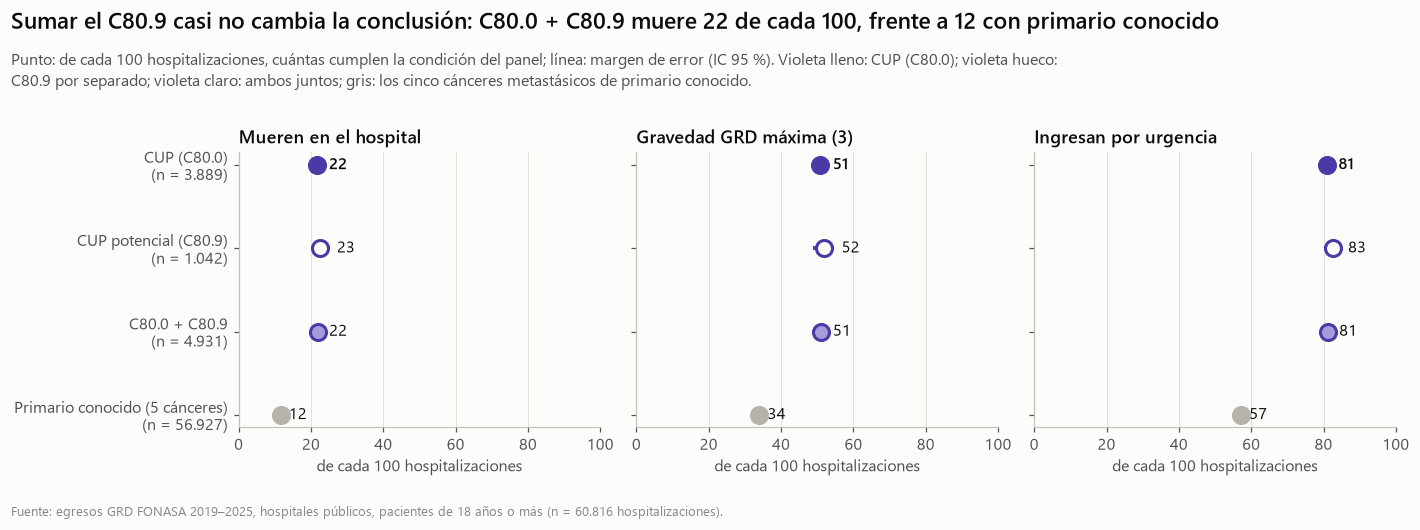

C80.9 con metástasis codificada (C77-C79): 73.2 %


,FALLECIDO,SEV3,URGENCIA,n,Estadía mediana,Edad mediana
CUP (C80.0),21.7,50.8,80.9,3889.0,9.0,68.8
CUP potencial (C80.9),22.6,51.7,82.6,1042.0,7.0,68.7
C80.0 + C80.9,21.9,51.0,81.3,4931.0,8.0,68.8
Primario conocido (5 cánceres),11.6,33.9,57.1,56927.0,5.0,66.0


In [21]:
conjuntos = {
    'CUP (C80.0)': df[df.GRUPO == 'CUP'],
    'CUP potencial (C80.9)': pot,
    'C80.0 + C80.9': pd.concat([df[df.GRUPO == 'CUP'], pot]),
    'Primario conocido (5 cánceres)': df[df.GRUPO != 'CUP'],
}
pot['TIENE_MET'] = pot[DIAG].fillna('').apply(lambda s: s.str[:3].isin(METASTASIS)).any(axis=1)
indicadores = [('FALLECIDO', 'Mueren en el hospital'), ('SEV3', 'Gravedad GRD máxima (3)'), ('URGENCIA', 'Ingresan por urgencia')]
sens = pd.DataFrame({k: {**{v: d[v].mean() * 100 for v, _ in indicadores}, 'n': len(d),
                         'Estadía mediana': d['DIAS_ESTADA'].median(), 'Edad mediana': d['EDAD'].median()}
                     for k, d in conjuntos.items()}).T
ESTILO_C = {'CUP (C80.0)': dict(color=COLOR_CUP, facecolor=COLOR_CUP),
            'CUP potencial (C80.9)': dict(color=COLOR_CUP, facecolor='#fcfcfb'),
            'C80.0 + C80.9': dict(color=COLOR_CUP, facecolor='#a59cdb'),
            'Primario conocido (5 cánceres)': dict(color=gris_marca, facecolor=gris_marca)}
filas_c = list(conjuntos)
figura, ejes = plt.subplots(1, 3, figsize=(13, 4.8), sharey=True)
yv = np.arange(len(filas_c))[::-1]
for eje, (v, nombre) in zip(ejes, indicadores):
    for yi, k in zip(yv, filas_c):
        d = conjuntos[k]
        lo_s, hi_s = ic_prop(d[v].sum(), len(d))
        eje.hlines(yi, lo_s, hi_s, color=ESTILO_C[k]['color'], linewidth=2.5)
        eje.scatter(sens.loc[k, v], yi, s=110, color=ESTILO_C[k]['facecolor'], edgecolor=ESTILO_C[k]['color'], linewidth=2, zorder=3)
        eje.text(hi_s + 2, yi, de100(sens.loc[k, v]), va='center', fontsize=10.5, color=tinta,
                 fontweight='semibold' if k == 'CUP (C80.0)' else 'normal')
    eje.set_xlim(0, 100)
    eje.set_title(nombre)
    eje.set_xlabel('de cada 100 hospitalizaciones')
    eje.grid(axis='y', visible=False)
ejes[0].set_yticks(yv, [f'{k}\n(n = {miles(sens.loc[k, "n"])})' for k in filas_c])
dif = sens.loc['C80.0 + C80.9', 'FALLECIDO'] - sens.loc['CUP (C80.0)', 'FALLECIDO']
brecha = sens.loc['C80.0 + C80.9', 'FALLECIDO'] - sens.loc['Primario conocido (5 cánceres)', 'FALLECIDO']
poner_titulo(figura,
             (f'Sumar el C80.9 {"casi no cambia" if abs(dif) < 2 else "cambia"} la conclusión: C80.0 + C80.9 muere '
              f'{de100(sens.loc["C80.0 + C80.9", "FALLECIDO"])} de cada 100, frente a {de100(sens.loc["Primario conocido (5 cánceres)", "FALLECIDO"])} '
              'con primario conocido'),
             'Punto: de cada 100 hospitalizaciones, cuántas cumplen la condición del panel; línea: margen de error (IC 95 %). '
             'Violeta lleno: CUP (C80.0); violeta hueco:\nC80.9 por separado; violeta claro: ambos juntos; gris: los cinco cánceres '
             'metastásicos de primario conocido.')
guardar(figura, 'P10_sensibilidad_c809')
print(f'C80.9 con metástasis codificada (C77-C79): {pot.TIENE_MET.mean() * 100:.1f} %')
sens.round(1)

**Respuesta.** No cambia. El C80.9 por separado (1.042 egresos) se comporta casi igual que el C80.0: mueren 23 de cada 100, 52 llegan con gravedad máxima y 83 por urgencia, y 73 de cada 100 tienen además una metástasis codificada. Al sumar ambos códigos la mortalidad queda en 22 de cada 100, frente a 12 en los cánceres de primario conocido. La conclusión es robusta a la definición de CUP. El análisis principal sigue usando solo C80.0, como recomienda la estrategia de identificación. En el dashboard, esto se traduce en un selector "C80.0 / C80.0 + C80.9".

### P11. ¿Cómo se distribuye el CUP en el territorio y hay zonas fuera de lo esperable?
Se responde en dos pasos: primero un **mapa por región** (la región del hospital, a partir de su Servicio de Salud) y después un **gráfico de embudo** por Servicio de Salud para ver si las diferencias de mortalidad superan al azar.

**Cómo leer los mapas.** Hay tres mapas de Chile, uno por indicador; en cada uno, más oscuro = más alto. Naranjo es la mortalidad (lo desfavorable) y violeta, los indicadores del CUP. La tabla de la derecha trae las cifras de cada región, de norte a sur, con un cuadrado del mismo color del mapa. El mapa no muestra Isla de Pascua ni Juan Fernández. En el notebook hay además un **mapa interactivo**: se elige el indicador en el menú y, al pasar el mouse por una región, se ven todas sus cifras (también en `figuras/P11a_mapa_regiones.html`).

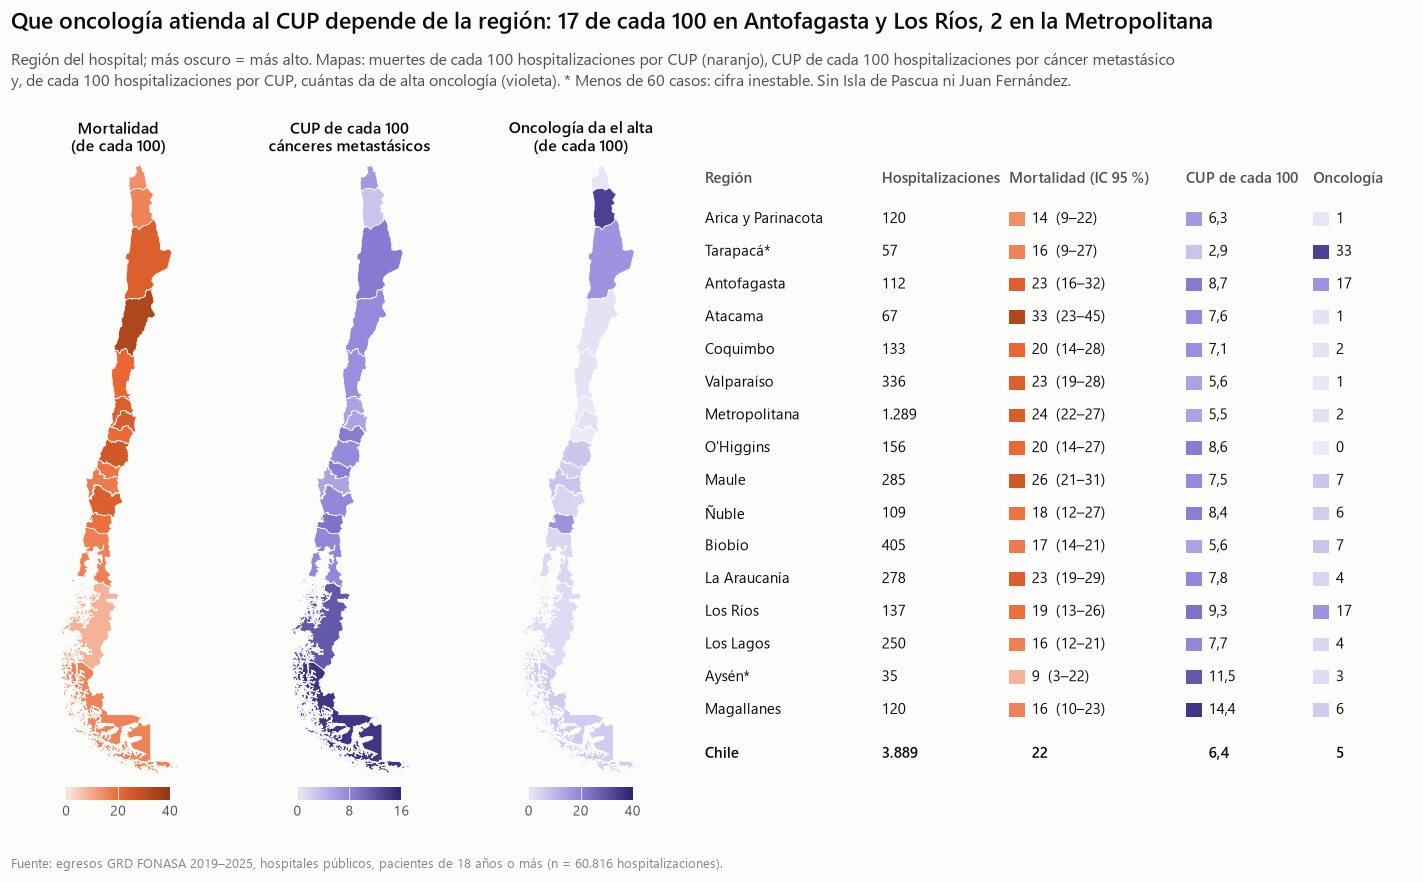

,region,n,mortalidad,lo,hi,peso_cup,oncologia,estancia
REGION,,,,,,,,
15,Arica y Parinacota,120,14.2,9.0,21.5,6.3,0.8,6.0
1,Tarapacá*,57,15.8,8.5,27.4,2.9,33.3,7.0
2,Antofagasta,112,23.2,16.4,31.8,8.7,17.0,8.5
3,Atacama,67,32.8,22.8,44.7,7.6,1.5,9.0
4,Coquimbo,133,20.3,14.3,27.9,7.1,1.5,8.0
5,Valparaíso,336,23.2,19.0,28.0,5.6,0.6,9.0
13,Metropolitana,1289,24.4,22.2,26.9,5.5,1.9,9.0
6,O'Higgins,156,19.9,14.4,26.8,8.6,0.0,7.0
7,Maule,285,26.0,21.2,31.4,7.5,7.0,8.0


In [22]:
import json
from matplotlib.collections import PolyCollection
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable

REGION_DE_SERVICIO = {
    'ARICA': 15, 'IQUIQUE': 1, 'ANTOFAGASTA': 2, 'ATACAMA': 3, 'COQUIMBO': 4,
    'VALPARAISO SAN ANTONIO': 5, 'VIÑA DEL MAR QUILLOTA': 5, 'ACONCAGUA': 5,
    'METROPOLITANO CENTRAL': 13, 'METROPOLITANO NORTE': 13, 'METROPOLITANO OCCIDENTE': 13,
    'METROPOLITANO ORIENTE': 13, 'METROPOLITANO SUR': 13, 'METROPOLITANO SURORIENTE': 13,
    'LIBERTADOR B. O HIGGINS': 6, 'DEL MAULE': 7, 'ÑUBLE': 16,
    'CONCEPCIÓN': 8, 'TALCAHUANO': 8, 'BIOBIO': 8, 'ARAUCO': 8,
    'ARAUCANÍA NORTE': 9, 'ARAUCANÍA SUR': 9, 'VALDIVIA': 14,
    'OSORNO': 10, 'DEL RELONCAVÍ': 10, 'CHILOÉ': 10, 'AYSEN': 11, 'MAGALLANES': 12}
NOMBRE_REGION = {15: 'Arica y Parinacota', 1: 'Tarapacá', 2: 'Antofagasta', 3: 'Atacama', 4: 'Coquimbo',
                 5: 'Valparaíso', 13: 'Metropolitana', 6: "O'Higgins", 7: 'Maule', 16: 'Ñuble', 8: 'Biobío',
                 9: 'La Araucanía', 14: 'Los Ríos', 10: 'Los Lagos', 11: 'Aysén', 12: 'Magallanes'}
ORDEN_REG = [15, 1, 2, 3, 4, 5, 13, 6, 7, 16, 8, 9, 14, 10, 11, 12]          # de norte a sur
N_ESTABLE = 60                                                             # menos casos = cifra inestable
# Polígonos de las 16 regiones (fuente: github.com/caracena/chile-geojson, base BCN; simplificado, sin islas oceánicas)
regiones_geo = json.load(open(CARPETA_PROYECTO / 'BD' / 'regiones_chile.geojson', encoding='utf-8'))
POLIGONOS = {f['properties']['codregion']: [np.array(p[0]) for p in f['geometry']['coordinates']]
             for f in regiones_geo['features']}

df['REGION'] = df['SERVICIO_SALUD'].map(REGION_DE_SERVICIO)
cup = df[df.GRUPO == 'CUP']
reg = cup.groupby('REGION').agg(n=('FALLECIDO', 'size'), muertes=('FALLECIDO', 'sum'),
                                estancia=('DIAS_ESTADA', 'median'),
                                oncologia=('ESPECIALIDAD', lambda s: (s == 'Oncología').mean() * 100))
reg['mortalidad'] = reg.muertes / reg.n * 100
reg['lo'], reg['hi'] = ic_prop(reg.muertes, reg.n)
reg['peso_cup'] = reg.n / df.groupby('REGION').size() * 100      # CUP de cada 100 hospitalizaciones de los 6 grupos
reg.index = reg.index.astype(int)
reg = reg.reindex(ORDEN_REG)
reg['region'] = [NOMBRE_REGION[c] + ('*' if n < N_ESTABLE else '') for c, n in zip(reg.index, reg.n)]

rampa_naranjo = LinearSegmentedColormap.from_list('naranjo', ['#fbe9e0', naranjo, '#8f3510'])
rampa_violeta = LinearSegmentedColormap.from_list('violeta', ['#ece9f8', '#8f84d9', '#2b2170'])
MAPAS = [('mortalidad', 'Mortalidad\n(de cada 100)', rampa_naranjo, 40),
         ('peso_cup', 'CUP de cada 100\ncánceres metastásicos', rampa_violeta, 16),
         ('oncologia', 'Oncología da el alta\n(de cada 100)', rampa_violeta, 40)]


def dibujar_mapa(eje, valores, rampa, vmax, titulo):
    """Mapa de Chile por región: más oscuro = valor más alto. Devuelve la escala para pintar la tabla."""
    norma = Normalize(0, vmax)
    for cod, anillos in POLIGONOS.items():
        v = valores.get(cod, np.nan)
        color = rampa(norma(v)) if pd.notna(v) else fondo_icono
        eje.add_collection(PolyCollection(anillos, facecolors=[color], edgecolors='#fcfcfb', linewidths=0.5))
    eje.set_xlim(-76, -66.3)
    eje.set_ylim(-56, -17.3)
    eje.set_aspect(1 / np.cos(np.deg2rad(37)))
    eje.axis('off')
    eje.set_title(titulo, fontsize=10.5, loc='center', pad=6)
    barra = eje.inset_axes([0.08, -0.035, 0.84, 0.022])
    figura.colorbar(ScalarMappable(norma, rampa), cax=barra, orientation='horizontal', ticks=[0, vmax / 2, vmax])
    barra.tick_params(labelsize=9, length=0)
    barra.set_xticklabels([f'{t:.0f}' for t in [0, vmax / 2, vmax]])
    barra.set_frame_on(False)
    return norma


figura = plt.figure(figsize=(13, 8))
rejilla = figura.add_gridspec(1, 4, width_ratios=[1, 1, 1, 3.3], wspace=0.05, left=0.01, right=0.99, bottom=0.115)
normas = {}
for k, (col, titulo, rampa, vmax) in enumerate(MAPAS):
    normas[col] = dibujar_mapa(figura.add_subplot(rejilla[0, k]), reg[col].to_dict(), rampa, vmax, titulo)

tabla = figura.add_subplot(rejilla[0, 3])
tabla.axis('off')
columnas = [(0.0, 'Región', None), (0.25, 'Hospitalizaciones', None), (0.43, 'Mortalidad (IC 95 %)', 'mortalidad'),
            (0.68, 'CUP de cada 100', 'peso_cup'), (0.86, 'Oncología', 'oncologia')]
alto_fila = 0.9 / (len(reg) + 1)
for x, titulo, _ in columnas:
    tabla.text(x, 0.97, titulo, fontsize=9.5, fontweight='semibold', color=gris_texto, va='center', transform=tabla.transAxes)
for i, (cod, r) in enumerate(reg.iterrows()):
    yy = 0.97 - (i + 1) * alto_fila - 0.012
    tabla.text(0.0, yy, r.region, fontsize=10, color=tinta, va='center', transform=tabla.transAxes)
    tabla.text(0.25, yy, miles(r.n), fontsize=10, color=tinta, va='center', transform=tabla.transAxes)
    textos = {'mortalidad': f'{de100(r.mortalidad)}  ({de100(r.lo)}–{de100(r.hi)})', 'peso_cup': coma(r.peso_cup),
              'oncologia': de100(r.oncologia)}
    for x, _, col in columnas[2:]:
        rampa = rampa_naranjo if col == 'mortalidad' else rampa_violeta
        tabla.add_patch(Rectangle((x, yy - 0.011), 0.022, 0.022, transform=tabla.transAxes,
                                  facecolor=rampa(normas[col](r[col])), edgecolor='none'))
        tabla.text(x + 0.032, yy, textos[col], fontsize=10, color=tinta, va='center', transform=tabla.transAxes)
y_nac = 0.97 - (len(reg) + 1) * alto_fila - 0.03
nacional = {'mortalidad': cup.FALLECIDO.mean() * 100, 'peso_cup': len(cup) / df.REGION.notna().sum() * 100,
            'oncologia': (cup.ESPECIALIDAD == 'Oncología').mean() * 100}
tabla.text(0.0, y_nac, 'Chile', fontsize=10, fontweight='semibold', color=tinta, va='center', transform=tabla.transAxes)
tabla.text(0.25, y_nac, miles(len(cup)), fontsize=10, fontweight='semibold', color=tinta, va='center', transform=tabla.transAxes)
for x, _, col in columnas[2:]:
    valor = coma(nacional[col]) if col == 'peso_cup' else de100(nacional[col])
    tabla.text(x + 0.032, y_nac, valor, fontsize=10, fontweight='semibold', color=tinta, va='center', transform=tabla.transAxes)

top_onc = reg[reg.n >= N_ESTABLE].nlargest(2, 'oncologia')
poner_titulo(figura,
             f'Que oncología atienda al CUP depende de la región: {de100(top_onc.oncologia.iloc[0])} de cada 100 en '
             f'{" y ".join(NOMBRE_REGION[c] for c in top_onc.index)}, {de100(reg.loc[13, "oncologia"])} en la Metropolitana',
             'Región del hospital; más oscuro = más alto. Mapas: muertes de cada 100 hospitalizaciones por CUP (naranjo), CUP de cada 100 '
             'hospitalizaciones por cáncer metastásico\ny, de cada 100 hospitalizaciones por CUP, cuántas da de alta oncología (violeta). '
             f'* Menos de {N_ESTABLE} casos: cifra inestable. Sin Isla de Pascua ni Juan Fernández.', ajustar=False)
guardar(figura, 'P11a_mapa_regiones')

if HAY_PLOTLY:
    escala_naranjo = [[0, '#fbe9e0'], [0.5, naranjo], [1, '#8f3510']]
    escala_violeta = [[0, '#ece9f8'], [0.5, '#8f84d9'], [1, '#2b2170']]
    INDICADORES = [('mortalidad', 'Mortalidad (de cada 100)', escala_naranjo),
                   ('n', 'Hospitalizaciones por CUP', escala_violeta),
                   ('peso_cup', 'CUP de cada 100 cánceres metastásicos', escala_violeta),
                   ('oncologia', 'Oncología da el alta (de cada 100)', escala_violeta),
                   ('estancia', 'Estadía mediana [días]', escala_violeta)]
    datos = np.c_[reg.region, [miles(v) for v in reg.n], [coma(v) for v in reg.mortalidad], [de100(v) for v in reg.lo],
                  [de100(v) for v in reg.hi], [coma(v) for v in reg.peso_cup], [coma(v) for v in reg.oncologia],
                  [f'{v:.0f}' for v in reg.estancia]]
    fig = go.Figure(go.Choropleth(
        geojson=regiones_geo, featureidkey='properties.codregion', locations=reg.index, z=reg['mortalidad'],
        colorscale=escala_naranjo, zmin=0, zmax=float(np.ceil(reg['mortalidad'].max() / 5) * 5), marker_line_color='#fcfcfb', marker_line_width=0.8, customdata=datos,
        colorbar=dict(title=dict(text=INDICADORES[0][1]), thickness=14, len=0.55),
        hovertemplate='<b>%{customdata[0]}</b><br>%{customdata[1]} hospitalizaciones por CUP (2019–2025)<br>'
                      'Mueren %{customdata[2]} de cada 100 (IC 95 %: %{customdata[3]} a %{customdata[4]})<br>'
                      'CUP de cada 100 cánceres metastásicos: %{customdata[5]}<br>'
                      'Oncología da el alta: %{customdata[6]} de cada 100<br>Estadía mediana: %{customdata[7]} días<extra></extra>'))
    botones = [dict(label=nombre, method='restyle',
                    args=[{'z': [reg[col].tolist()], 'colorscale': [escala], 'zmin': [0], 'zmax': [float(np.ceil(reg[col].max() / 5) * 5)],
                           'colorbar.title.text': nombre}]) for col, nombre, escala in INDICADORES]
    plotly_base(fig, 'Mapa del CUP por región (2019–2025)',
                'Elige el indicador en el menú y pasa el mouse por una región para ver todas sus cifras. * Menos de 60 casos.', alto=980)
    fig.update_layout(width=900, updatemenus=[dict(buttons=botones, direction='down', x=0.02, y=0.98, xanchor='left',
                                                    yanchor='top', bgcolor='white', bordercolor='#c3c2b7')])
    fig.update_geos(fitbounds='locations', visible=False, projection_type='mercator', bgcolor='#fcfcfb')
    fig.write_html(CARPETA_FIG / 'P11a_mapa_regiones.html', include_plotlyjs='cdn')
    fig.show()
reg[['region', 'n', 'mortalidad', 'lo', 'hi', 'peso_cup', 'oncologia', 'estancia']].round(1)

**Cómo leer el gráfico de embudo (funnel plot).** Cada punto es un Servicio de Salud: a la derecha los que atienden más casos de CUP y arriba los que tienen más mortalidad. La línea horizontal es la mortalidad nacional del CUP. Las curvas forman un embudo: con pocos casos la mortalidad varía mucho por azar, así que los límites son anchos; con muchos casos se estrechan. Un punto **fuera del embudo** tiene una mortalidad distinta de la que daría el azar. Es el método estándar para comparar hospitales sin hacer un ranking engañoso (Spiegelhalter, *Statistics in Medicine*, 2005). Los límites son binomiales exactos al 95 % y al 99,8 %.

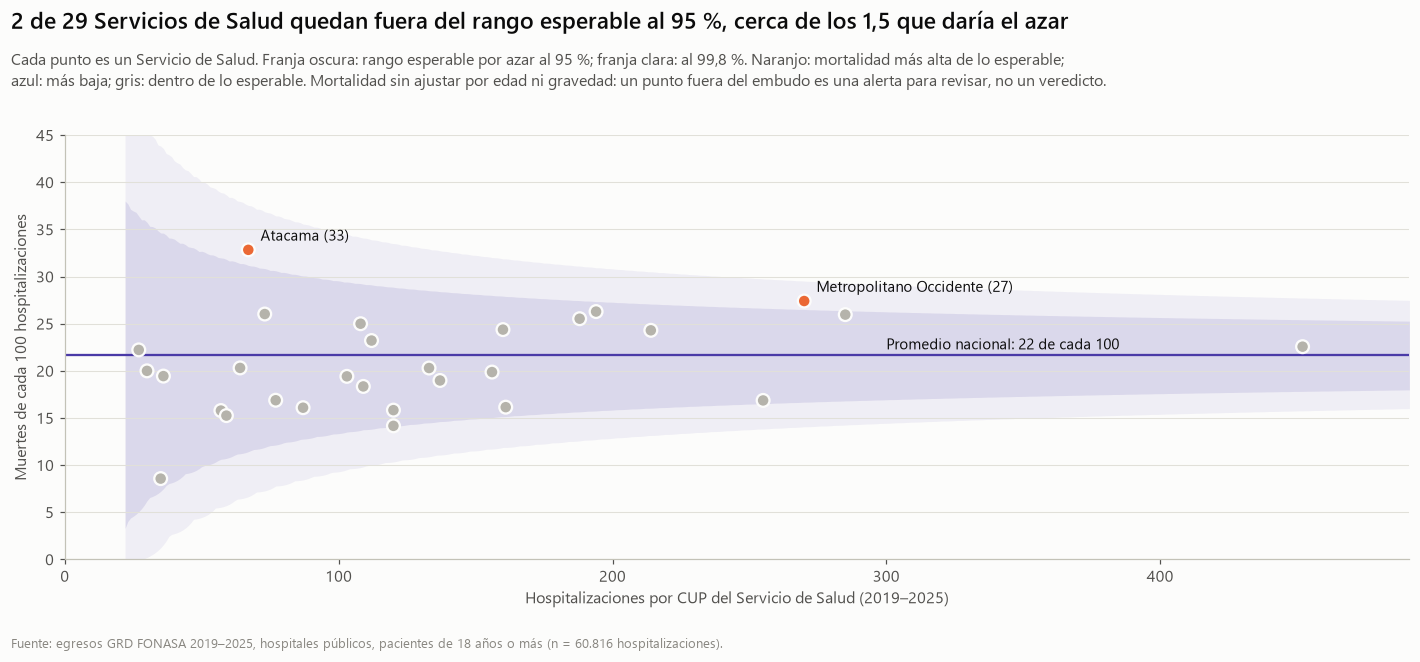

,n,muertes,pct,inf95,sup95,inf998,sup998,estado
SERVICIO_SALUD,,,,,,,,
METROPOLITANO SURORIENTE,452,102,22.6,17.8,25.4,15.8,27.7,dentro
DEL MAULE,285,74,26.0,16.8,26.4,14.3,29.3,dentro
METROPOLITANO OCCIDENTE,270,74,27.4,16.7,26.5,14.1,29.5,más alta
CONCEPCIÓN,255,43,16.9,16.5,26.6,13.8,29.8,dentro
ARAUCANÍA SUR,214,52,24.3,16.0,27.1,13.1,30.5,dentro
METROPOLITANO CENTRAL,194,51,26.3,15.7,27.3,12.7,30.9,dentro
METROPOLITANO ORIENTE,188,48,25.5,15.7,27.5,12.6,31.1,dentro
DEL RELONCAVÍ,161,26,16.1,15.2,27.9,11.9,31.9,dentro
VALPARAISO SAN ANTONIO,160,39,24.4,15.1,27.9,11.9,31.9,dentro


In [23]:
cup = df[df.GRUPO == 'CUP']
terr = cup.groupby('SERVICIO_SALUD').agg(n=('FALLECIDO', 'size'), muertes=('FALLECIDO', 'sum'))
terr['pct'] = terr.muertes / terr.n * 100
p0 = cup['FALLECIDO'].mean()
ns = np.arange(max(5, terr.n.min() - 5), terr.n.max() + 40)


def limite(q, n=ns):
    """Límite binomial exacto interpolado (Spiegelhalter 2005): curva suave en vez de escalones."""
    n = np.asarray(n, float)
    r = stats.binom.ppf(q, n, p0)
    alfa = (stats.binom.cdf(r, n, p0) - q) / stats.binom.pmf(r, n, p0)
    return (r - alfa) / n * 100


for q, col in [(0.025, 'inf95'), (0.975, 'sup95'), (0.001, 'inf998'), (0.999, 'sup998')]:
    terr[col] = limite(q, terr.n)
terr['estado'] = np.select([terr.pct > terr.sup95, terr.pct < terr.inf95], ['más alta', 'más baja'], 'dentro')
fuera = terr[terr.estado != 'dentro']
fuera998 = terr[(terr.pct > terr.sup998) | (terr.pct < terr.inf998)]
esperados = 0.05 * len(terr)
color_estado = {'más alta': naranjo, 'más baja': azul, 'dentro': gris_marca}

figura, eje = plt.subplots(figsize=(13, 6))
eje.fill_between(ns, limite(0.001), limite(0.999), color=COLOR_CUP, alpha=0.07, linewidth=0)
eje.fill_between(ns, limite(0.025), limite(0.975), color=COLOR_CUP, alpha=0.12, linewidth=0)
eje.axhline(p0 * 100, color=COLOR_CUP, linewidth=1.5)
eje.text(300, p0 * 100 + 0.6, f'Promedio nacional: {de100(p0 * 100)} de cada 100', ha='left', fontsize=10, color=tinta)
eje.scatter(terr.n, terr.pct, s=70, c=[color_estado[e] for e in terr.estado], edgecolor='#fcfcfb', linewidth=1.5, zorder=3)
for nombre, r in fuera.iterrows():
    eje.annotate(f'{nombre.title()} ({de100(r.pct)})', (r.n, r.pct), xytext=(8, 6 if r.estado == 'más alta' else -12),
                 textcoords='offset points', fontsize=10, color=tinta)
eje.set_xlim(0, ns[-1])
eje.set_ylim(0, max(45, terr.pct.max() + 5))
eje.set_xlabel('Hospitalizaciones por CUP del Servicio de Salud (2019–2025)')
eje.set_ylabel('Muertes de cada 100 hospitalizaciones')
eje.grid(axis='x', visible=False)
poner_titulo(figura,
             f'{len(fuera)} de {len(terr)} Servicios de Salud quedan fuera del rango esperable al 95 %, cerca de los '
             f'{esperados:.1f} que daría el azar'.replace('.', ','),
             'Cada punto es un Servicio de Salud. Franja oscura: rango esperable por azar al 95 %; franja clara: al 99,8 %. '
             'Naranjo: mortalidad más alta de lo esperable;\nazul: más baja; gris: dentro de lo esperable. '
             'Mortalidad sin ajustar por edad ni gravedad: un punto fuera del embudo es una alerta para revisar, no un veredicto.')
guardar(figura, 'P11_territorio_funnel')

if HAY_PLOTLY:
    fig = go.Figure()
    for q1, q2, a in [(0.001, 0.999, 0.07), (0.025, 0.975, 0.12)]:
        fig.add_trace(go.Scatter(x=np.r_[ns, ns[::-1]], y=np.r_[limite(q1), limite(q2)[::-1]], fill='toself', mode='none',
                                 fillcolor=f'rgba(74,58,167,{a})', hoverinfo='skip', showlegend=False))
    fig.add_hline(y=p0 * 100, line_color=COLOR_CUP)
    fig.add_trace(go.Scatter(
        x=terr.n, y=terr.pct, mode='markers', showlegend=False,
        marker=dict(size=11, color=[color_estado[e] for e in terr.estado], line=dict(color='#fcfcfb', width=1.5)),
        customdata=np.c_[terr.index.str.title(), terr.muertes, terr.estado],
        hovertemplate='<b>%{customdata[0]}</b><br>%{x} hospitalizaciones · %{customdata[1]} muertes<br>'
                      '%{y:.1f} de cada 100 (%{customdata[2]} de lo esperable)<extra></extra>'))
    plotly_base(fig, f'Mortalidad CUP por Servicio de Salud: {len(fuera)} de {len(terr)} fuera del rango esperable al 95 %',
                'Pasa el mouse por cada punto. Franjas: rango esperable por azar (95 % y 99,8 %). Prototipo de la pestaña Territorio.',
                alto=600)
    fig.update_xaxes(title='Hospitalizaciones por CUP (2019–2025)', gridcolor='#e1e0d9', range=[0, ns[-1]])
    fig.update_yaxes(title='Muertes de cada 100 hospitalizaciones', gridcolor='#e1e0d9', range=[0, max(45, terr.pct.max() + 5)])
    fig.write_html(CARPETA_FIG / 'P11_territorio_funnel.html', include_plotlyjs='cdn')
    fig.show()
terr.sort_values('n', ascending=False).round(1)

**Respuesta.** El volumen sigue a la población: la Metropolitana reúne 1.289 hospitalizaciones por CUP (33 de cada 100). Pero el mapa muestra dos patrones que no dependen del tamaño de cada región:
- **Quién atiende al CUP cambia mucho según la región.** Oncología da el alta en 17 de cada 100 hospitalizaciones en Antofagasta y Los Ríos (33 en Tarapacá, con pocos casos), pero en 2 o menos en Arica, Atacama, Coquimbo, Valparaíso, la Metropolitana y O'Higgins. Esto sugiere que la derivación del CUP a oncología depende de cómo se organiza cada red, no del paciente.
- **En el extremo sur el CUP pesa más** dentro de los cánceres metastásicos: 11 a 14 de cada 100 en Aysén y Magallanes, frente a 6 en el país.

La mortalidad por región va de 9 de cada 100 (Aysén, con solo 35 casos) a 33 (Atacama). En 11 de las 16 regiones el margen de error incluye el promedio nacional (22); Atacama y la Metropolitana quedan por encima, y Arica, Biobío y Los Lagos por debajo. El gráfico de embudo por Servicio de Salud lo precisa: solo 2 de 29 servicios quedan sobre el rango esperable al 95 %, **Atacama (33 de cada 100, con 67 casos)** y **Metropolitano Occidente (27 de cada 100, con 270 casos)**, cuando por azar se esperarían 1,5, y ninguno queda fuera del límite de 99,8 %. Como la mortalidad no está ajustada por edad ni gravedad, son **alertas para revisar**, no evidencia de peor atención.

El mapa y el embudo son la base de la pestaña Territorio del dashboard; las versiones interactivas están en `figuras/P11a_mapa_regiones.html` y `figuras/P11_territorio_funnel.html`. La región es la del hospital, no la del domicilio del paciente; no se calculan tasas por habitante.

## 8. Conclusiones y uso en el dashboard
1. **Magnitud (P1):** el CUP suma 3.889 hospitalizaciones en 2019–2025 (unas 556 al año) y en 2025 ocupó 8.195 días-cama. Cayó 24 % con la pandemia y en 2025 ya supera a 2019.
2. **Calidad de la definición (P2):** solo 20 de cada 100 egresos CUP tienen el C80.0 como diagnóstico principal; buscar en los 35 diagnósticos es indispensable.
3. **Perfil (P3):** mediana de 69 años, 54 de cada 100 son mujeres y 75 de cada 100 son FONASA A o B.
4. **Metástasis (P4):** hígado, peritoneo, pulmón y hueso; con metástasis pulmonar o hepática la mortalidad sube a 29–31 de cada 100.
5. **Atención (P5):** llega por urgencia y lo atiende medicina interna; oncología da el alta en solo 5 de cada 100 hospitalizaciones.
6. **Salida (P6):** episodio único y grave: 22 de cada 100 mueren, pocos reingresan y a 6 de cada 100 pacientes se les encuentra después el primario.
7. **Recursos (P7):** la estadía más larga (mediana de 9 días) y la mayor proporción en UCI.
8. **Comparación (P8–P9):** el CUP muere tanto como pulmón y más que los otros cuatro cánceres, también a igual edad, sexo, gravedad y tipo de ingreso (15 frente a 10–13 muertes ajustadas de cada 100).
9. **Sensibilidad (P10):** sumar el C80.9 no cambia la conclusión.
10. **Territorio (P11):** que oncología atienda al CUP depende de la región (17 de cada 100 en Antofagasta y Los Ríos, 2 en la Metropolitana); la mortalidad casi no varía más de lo esperable (2 de 29 Servicios de Salud sobre el rango).

| Pregunta | Dónde va en el *Dashboard CUP Chile* |
|---|---|
| P1 | KPI de hospitalizaciones, días-cama y mortalidad con variación frente al año anterior; gráfico de evolución anual |
| P2 | Nota metodológica y filtro "diagnóstico principal / cualquier posición" |
| P3 | Panel de perfil: pirámide de edad y sexo, previsión |
| P4 | Panel de sitios de metástasis con la mortalidad de cada sitio |
| P5–P6 | Pestaña Análisis: diagrama de trayectoria (llegada → especialidad → salida) y KPI de reingreso |
| P7 | KPI de estadía mediana y paso por UCI |
| P8–P9 | Pestaña Comparaciones: tabla del CUP frente a los cinco cánceres y mortalidad ajustada |
| P10 | Selector de definición "C80.0 / C80.0 + C80.9" |
| P11 | Pestaña Territorio: mapa interactivo por región (indicador a elegir) y gráfico de embudo por Servicio de Salud |

## 9. Limitaciones
- Solo se observa la **mortalidad intrahospitalaria**: quien muere después del alta no aparece.
- La unidad es el **egreso**; un paciente puede tener varios. El ID cifrado cambia entre 2020 y 2021, así que el seguimiento por paciente se hace en 2021–2025.
- En **2025 la edad es aproximada** (tramos de 5 años) y se excluye el tramo de 15 a 19 años.
- Los diagnósticos 2 a 35 pueden ser antecedentes; *metastásico* depende de que la metástasis esté codificada.
- El reingreso a 30 días solo cuenta hospitalizaciones que vuelven a caer en estos grupos de cáncer.
- La comparación territorial no está ajustada por edad ni gravedad.
- Solo incluye hospitales públicos con GRD; no hay datos de clínicas privadas.